<a href="https://colab.research.google.com/github/Destinywaya9/ZERO/blob/main/QTET_Creative_Simulation_Pack_III.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QTET Colab — Analytical Upgrade Pack

A focused companion to the full simulation suite. This notebook packages the strongest follow-up experiments identified in the results review.

**Canon boundary:** Tensor P2 is held fixed exactly as `3,3 → 0,0 → 0,1 → 1,2 → 2,1 → 1,0 → 0,0 → Delay(200)`. All null models, thresholds, embedding formulas, graph rules, classifiers, corruption rates, and plotting choices below are **simulation controls**, not new canonical definitions of QTET/QTL-Sphere, Tensor P2/P3, LDCT, DiamondFlex, QRTM, or Wilson.

Included upgrades:
1. P2 Predictive Information Horizon
2. P3 Dimensional Survival vs. Null Embeddings
3. LDCT Monte Carlo Cut Robustness
4. P2 Mutation Detection Metrics
5. Wilson Contradiction-Aware Context Rejection (toy rule)
6. Noisy P2 Motif Recovery

## 0. Setup and Canon Lock

In [ ]:
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy import stats
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from IPython.display import display

SEED = 2026
rng = np.random.default_rng(SEED)

CANONICAL_P2 = (
    (3, 3),
    (0, 0),
    (0, 1),
    (1, 2),
    (2, 1),
    (1, 0),
    (0, 0),
)
DELAY = 200

P2_LABELS = [f"{x},{y}" for x, y in CANONICAL_P2]
DELAY_TOKEN = f"Delay({DELAY})"
P2_CYCLE = P2_LABELS + [DELAY_TOKEN]
UNIQUE_STATES = list(dict.fromkeys(P2_CYCLE))

assert CANONICAL_P2 == (
    (3, 3), (0, 0), (0, 1), (1, 2), (2, 1), (1, 0), (0, 0)
)
assert DELAY == 200

print("Canon lock passed:")
print(" -> ".join(P2_CYCLE))

Canon lock passed:
3,3 -> 0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0 -> 0,0 -> Delay(200)


## 1. P2 Predictive Information Horizon

This asks how much immediate temporal context is required to predict the next event in an exact recurrent P2+Delay stream. We calculate

\[
H(X_{t+1}\mid X_t,\ldots,X_{t-k+1})
\]

for context length \(k\). This is ordinary information theory applied to the symbolic simulation stream; it is not a thermodynamic entropy claim.

,context_length,conditional_entropy_bits,zero_uncertainty
0,1,0.250016,False
1,2,0.000000,True
2,3,0.000000,True
3,4,0.000000,True
4,5,0.000000,True
5,6,0.000000,True
6,7,0.000000,True
7,8,0.000000,True


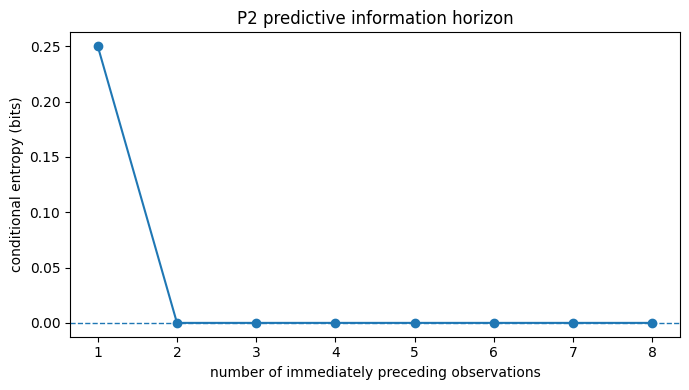

First zero-uncertainty context length: 2


In [ ]:
def repeated_p2(cycles=2000):
    return P2_CYCLE * int(cycles)


def conditional_entropy_context(seq, k):
    if k < 1:
        raise ValueError("k must be >= 1")
    joint = Counter()
    context_counts = Counter()
    total = 0
    for i in range(k, len(seq)):
        context = tuple(seq[i-k:i])
        nxt = seq[i]
        joint[(context, nxt)] += 1
        context_counts[context] += 1
        total += 1
    H = 0.0
    for (context, nxt), n in joint.items():
        p_joint = n / total
        p_next_given_context = n / context_counts[context]
        H -= p_joint * math.log2(p_next_given_context)
    return H


def predictive_information_horizon(max_context=8, cycles=2000):
    seq = repeated_p2(cycles)
    rows = []
    for k in range(1, max_context + 1):
        H = conditional_entropy_context(seq, k)
        rows.append({
            "context_length": k,
            "conditional_entropy_bits": H,
            "zero_uncertainty": bool(np.isclose(H, 0.0, atol=1e-12)),
        })
    return pd.DataFrame(rows)

horizon_df = predictive_information_horizon()
display(horizon_df)

plt.figure(figsize=(7, 4))
plt.plot(horizon_df["context_length"], horizon_df["conditional_entropy_bits"], marker="o")
plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("number of immediately preceding observations")
plt.ylabel("conditional entropy (bits)")
plt.title("P2 predictive information horizon")
plt.tight_layout()
plt.show()

first_zero = horizon_df.loc[horizon_df.zero_uncertainty, "context_length"].min()
print("First zero-uncertainty context length:", int(first_zero))

### Interpretation
The first-order stream retains uncertainty because the coordinate `0,0` occurs in two traversal positions with different successors. The experiment tests whether finite temporal context resolves that observational ambiguity.

## 2. P3 Dimensional Survival vs. Null Embeddings

,embedding_dim,p2_derived_rho,null_mean_rho,null_sd_rho,empirical_p_null_ge_observed
0,3,0.980984,1.000000,0.000000,1.000000
1,4,0.950293,0.988643,0.013146,0.980050
2,8,0.997403,0.964162,0.028128,0.014963
3,16,0.977922,0.939685,0.039708,0.122195
4,32,0.988312,0.921390,0.044476,0.007481
5,64,0.946753,0.900205,0.050689,0.169576


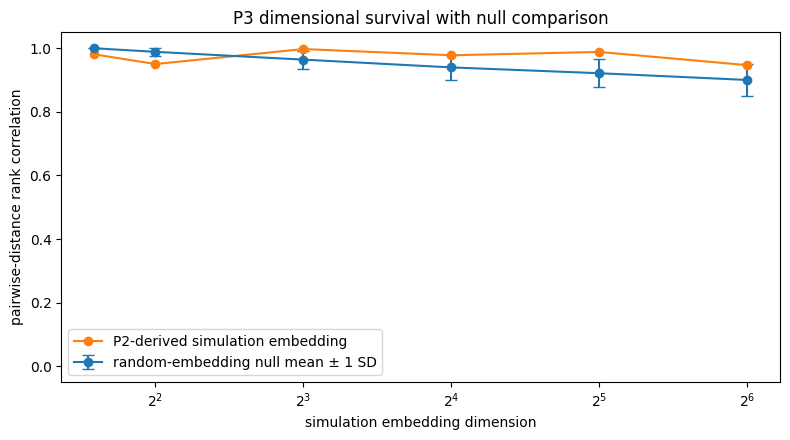

In [ ]:
def p3_sim_embedding(dim, seed=13):
    xy = np.asarray(CANONICAL_P2, dtype=float)
    step = np.arange(len(xy), dtype=float)
    feats = [
        xy[:, 0], xy[:, 1], xy.sum(1), xy[:, 0] - xy[:, 1],
        np.linalg.norm(xy, axis=1)
    ]
    k = 1
    while len(feats) < dim:
        feats.append(
            np.sin(k * (step + 1) / 2.0)
            + np.cos((k + 1) * (xy[:, 0] + 1) / 3.0)
        )
        k += 1
    X = np.column_stack(feats[:dim])
    local_rng = np.random.default_rng(seed + dim)
    Q, _ = np.linalg.qr(local_rng.normal(size=(dim, dim)))
    return X @ Q


def projection_rank_survival(X):
    d_full = pdist(X)
    n_components = min(3, X.shape[1], len(X) - 1)
    Y = PCA(n_components=n_components).fit_transform(X)
    d_proj = pdist(Y)
    return float(stats.spearmanr(d_full, d_proj).statistic)


def p3_survival_null_test(dimensions=(3,4,8,16,32,64), null_trials=400, seed=2026):
    local_rng = np.random.default_rng(seed)
    rows = []
    null_rows = []
    n_events = len(CANONICAL_P2)
    for dim in dimensions:
        observed = projection_rank_survival(p3_sim_embedding(dim))
        null = np.empty(null_trials)
        for trial in range(null_trials):
            X0 = local_rng.normal(size=(n_events, dim))
            null[trial] = projection_rank_survival(X0)
        p_emp = (1 + np.sum(null >= observed)) / (null_trials + 1)
        rows.append({
            "embedding_dim": dim,
            "p2_derived_rho": observed,
            "null_mean_rho": float(np.mean(null)),
            "null_sd_rho": float(np.std(null, ddof=1)),
            "empirical_p_null_ge_observed": float(p_emp),
        })
        null_rows.extend({"embedding_dim": dim, "rho": float(v)} for v in null)
    return pd.DataFrame(rows), pd.DataFrame(null_rows)

p3_null_summary, p3_null_trials = p3_survival_null_test()
display(p3_null_summary)

plt.figure(figsize=(8, 4.5))
plt.errorbar(
    p3_null_summary["embedding_dim"],
    p3_null_summary["null_mean_rho"],
    yerr=p3_null_summary["null_sd_rho"],
    marker="o", capsize=4, label="random-embedding null mean ± 1 SD"
)
plt.plot(
    p3_null_summary["embedding_dim"],
    p3_null_summary["p2_derived_rho"],
    marker="o", label="P2-derived simulation embedding"
)
plt.xscale("log", base=2)
plt.ylim(-0.05, 1.05)
plt.xlabel("simulation embedding dimension")
plt.ylabel("pairwise-distance rank correlation")
plt.title("P3 dimensional survival with null comparison")
plt.legend()
plt.tight_layout()
plt.show()

The null comparison is the important upgrade: high projection survival by itself can be partly guaranteed by the small number of events and PCA. This comparison asks whether the P2-derived simulation embedding preserves pairwise-distance ordering more strongly than generic random embeddings of the same shape.

## 3. LDCT Monte Carlo Cut Robustness

,strategy,fraction_removed,mean_lcc_fraction_of_original,sd_lcc,trials
0,highest_degree_nodes,0.00,1.000000,0.000000,1
1,random_nodes,0.00,1.000000,0.000000,250
2,highest_degree_nodes,0.05,0.950000,0.000000,1
3,random_nodes,0.05,0.943111,0.054465,250
4,highest_degree_nodes,0.10,0.900000,0.000000,1
5,random_nodes,0.10,0.898156,0.028111,250
6,highest_degree_nodes,0.15,0.850000,0.000000,1
7,random_nodes,0.15,0.824867,0.090767,250
8,highest_degree_nodes,0.20,0.800000,0.000000,1
9,random_nodes,0.20,0.766444,0.098789,250


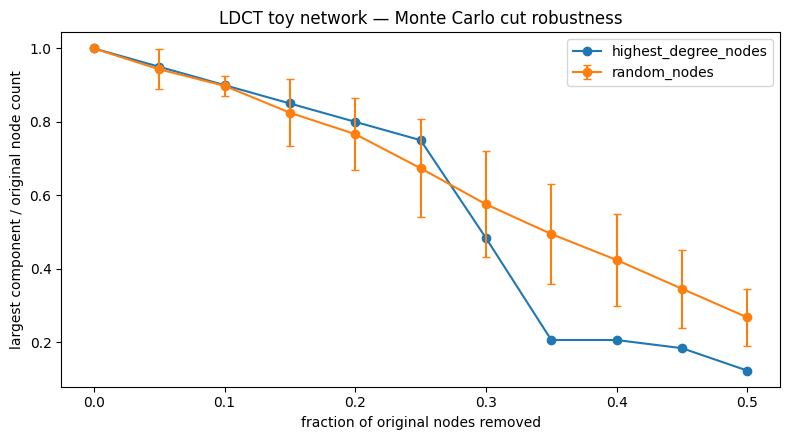

Synthetic LDCT graph: 180 nodes, 889 edges


In [ ]:
def ldct_emergence_toy(n=180, coherence_threshold=0.04, seed=20):
    local_rng = np.random.default_rng(seed)
    pos = local_rng.random((n, 2))
    coherence = local_rng.random(n)
    G = nx.Graph()
    G.add_nodes_from(range(n))
    for i in range(n):
        G.nodes[i]["pos"] = tuple(pos[i])
        G.nodes[i]["coherence"] = float(coherence[i])
    for i in range(n):
        for j in range(i + 1, n):
            similarity = abs(coherence[i] - coherence[j])
            distance = np.linalg.norm(pos[i] - pos[j])
            if similarity < coherence_threshold and distance > 0.35:
                G.add_edge(i, j, distance=float(distance), similarity=float(similarity))
    return G


def largest_component_fraction_relative_to_original(H, original_n):
    if H.number_of_nodes() == 0:
        return 0.0
    if H.number_of_edges() == 0:
        return 1.0 / original_n
    return max(len(c) for c in nx.connected_components(H)) / original_n


def ldct_cut_monte_carlo(
    fractions=np.linspace(0, 0.5, 11),
    random_trials=250,
    seed=2026
):
    G = ldct_emergence_toy()
    nodes = np.array(list(G.nodes()))
    original_n = len(nodes)
    degree_order = sorted(G.nodes(), key=dict(G.degree()).get, reverse=True)
    local_rng = np.random.default_rng(seed)
    rows = []

    for frac in fractions:
        k = int(round(frac * original_n))

        targeted = G.copy()
        if k:
            targeted.remove_nodes_from(degree_order[:k])
        rows.append({
            "strategy": "highest_degree_nodes",
            "fraction_removed": frac,
            "mean_lcc_fraction_of_original": largest_component_fraction_relative_to_original(targeted, original_n),
            "sd_lcc": 0.0,
            "trials": 1,
        })

        vals = []
        for _ in range(random_trials):
            H = G.copy()
            if k:
                remove = local_rng.choice(nodes, size=k, replace=False).tolist()
                H.remove_nodes_from(remove)
            vals.append(largest_component_fraction_relative_to_original(H, original_n))
        rows.append({
            "strategy": "random_nodes",
            "fraction_removed": frac,
            "mean_lcc_fraction_of_original": float(np.mean(vals)),
            "sd_lcc": float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0,
            "trials": random_trials,
        })

    return G, pd.DataFrame(rows)

G_ldct, ldct_mc = ldct_cut_monte_carlo()
display(ldct_mc)

plt.figure(figsize=(8, 4.5))
for strategy, q in ldct_mc.groupby("strategy"):
    if strategy == "random_nodes":
        plt.errorbar(
            q["fraction_removed"], q["mean_lcc_fraction_of_original"],
            yerr=q["sd_lcc"], marker="o", capsize=3, label=strategy
        )
    else:
        plt.plot(q["fraction_removed"], q["mean_lcc_fraction_of_original"], marker="o", label=strategy)
plt.xlabel("fraction of original nodes removed")
plt.ylabel("largest component / original node count")
plt.title("LDCT toy network — Monte Carlo cut robustness")
plt.legend()
plt.tight_layout()
plt.show()

print("Synthetic LDCT graph:", G_ldct.number_of_nodes(), "nodes,", G_ldct.number_of_edges(), "edges")

This fixes the earlier non-monotonic interpretability problem caused by drawing only one unrelated random-removal sample at each fraction. The random curve is now a Monte Carlo expectation with uncertainty.

## 4. P2 Mutation Detection — Event-Level Metrics

In [ ]:
def p2_context_whitelist():
    stream = P2_CYCLE * 4
    return {
        (stream[i - 1], stream[i], stream[i + 1])
        for i in range(1, len(stream) - 1)
    }


def mutate_p2_stream(cycles=100, mutation_rate=0.03, seed=5):
    local_rng = np.random.default_rng(seed)
    stream = (P2_CYCLE * cycles).copy()
    positions = []
    for i in range(1, len(stream) - 1):
        if local_rng.random() < mutation_rate:
            alternatives = [x for x in UNIQUE_STATES if x != stream[i]]
            stream[i] = local_rng.choice(alternatives)
            positions.append(i)
    return stream, positions


def detect_p2_mutation_contexts(stream):
    whitelist = p2_context_whitelist()
    return [
        i for i in range(1, len(stream) - 1)
        if (stream[i-1], stream[i], stream[i+1]) not in whitelist
    ]


def cluster_indices(indices):
    if not indices:
        return []
    indices = sorted(set(indices))
    clusters = [[indices[0]]]
    for x in indices[1:]:
        if x <= clusters[-1][-1] + 1:
            clusters[-1].append(x)
        else:
            clusters.append([x])
    return clusters


def mutation_event_metrics(cycles=100, mutation_rate=0.03, seed=5, tolerance=1):
    stream, truth = mutate_p2_stream(cycles, mutation_rate, seed)
    flagged = detect_p2_mutation_contexts(stream)
    clusters = cluster_indices(flagged)
    centers = np.array([int(round(np.mean(c))) for c in clusters], dtype=int)
    truth_arr = np.array(truth, dtype=int)

    matched_truth = set()
    matched_centers = set()
    localization = []
    for ci, center in enumerate(centers):
        if len(truth_arr) == 0:
            continue
        j = int(np.argmin(np.abs(truth_arr - center)))
        err = abs(int(truth_arr[j]) - int(center))
        if err <= tolerance and j not in matched_truth:
            matched_truth.add(j)
            matched_centers.add(ci)
            localization.append(err)

    tp = len(matched_truth)
    fn = len(truth) - tp
    fp = len(centers) - len(matched_centers)
    precision = tp / (tp + fp) if (tp + fp) else 1.0
    recall = tp / (tp + fn) if (tp + fn) else 1.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

    summary = pd.DataFrame([{
        "injected_mutations": len(truth),
        "raw_flagged_contexts": len(flagged),
        "flag_clusters": len(clusters),
        "event_true_positives": tp,
        "event_false_positives": fp,
        "event_false_negatives": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "mean_localization_error_steps": float(np.mean(localization)) if localization else np.nan,
    }])
    return summary, truth, flagged, clusters

mutation_summary, mutation_truth, mutation_flags, mutation_clusters = mutation_event_metrics()
display(mutation_summary)
print("First injected mutation positions:", mutation_truth[:15])
print("First flag clusters:", mutation_clusters[:10])

,injected_mutations,raw_flagged_contexts,flag_clusters,event_true_positives,event_false_positives,event_false_negatives,precision,recall,f1,mean_localization_error_steps
0,32,93,30,30,0,2,1.0,0.9375,0.967742,0.033333


First injected mutation positions: [30, 31, 48, 87, 111, 127, 158, 177, 201, 234, 243, 290, 305, 309, 382]
First flag clusters: [[29, 30, 31, 32], [47, 48, 49], [86, 87, 88], [110, 111, 112], [126, 127, 128], [157, 158, 159], [176, 177, 178], [200, 201, 202], [233, 234, 235], [242, 243, 244]]


The detector still works on three-event windows, but the evaluation now collapses adjacent flags into anomaly events and reports precision, recall, F1, and localization error. This avoids counting several overlapping windows around one mutation as several separate discoveries.

## 5. Wilson Contradiction-Aware Context Rejection — Toy Rule

In [ ]:
def contradiction_aware_context_rule(query, candidates, critical_fields=("direction",)):
    """
    Toy context-consistency rule only.
    It is NOT a definition of Wilson's canonical logic.
    """
    rows = []
    for name, candidate in candidates.items():
        shared = set(query) & set(candidate)
        agreements = sum(query[k] == candidate[k] for k in shared)
        conflicts = [k for k in shared if query[k] != candidate[k]]
        critical_conflicts = [k for k in conflicts if k in critical_fields]
        coverage = len(shared) / max(len(query), 1)
        agreement_fraction = agreements / max(len(shared), 1)
        accepted = coverage >= 0.66 and agreement_fraction >= 0.80 and not critical_conflicts
        rows.append({
            "candidate": name,
            "coverage": coverage,
            "agreement_fraction": agreement_fraction,
            "conflicting_fields": ", ".join(conflicts) if conflicts else "none",
            "critical_conflict": bool(critical_conflicts),
            "accepted_under_toy_rule": bool(accepted),
        })
    return pd.DataFrame(rows).sort_values(
        ["accepted_under_toy_rule", "agreement_fraction", "coverage"],
        ascending=[False, False, False]
    )

query = {"event": "motion", "object": "object", "direction": "left"}
candidates = {
    "context_A": {"event": "motion", "object": "object", "direction": "left"},
    "context_B": {"event": "temperature", "object": "room", "direction": "warm"},
    "context_C": {"event": "motion", "object": "object", "direction": "right"},
}

wilson_context_demo = contradiction_aware_context_rule(query, candidates)
display(wilson_context_demo)

,candidate,coverage,agreement_fraction,conflicting_fields,critical_conflict,accepted_under_toy_rule
0,context_A,1.0,1.000000,none,False,True
2,context_C,1.0,0.666667,direction,True,False
1,context_B,1.0,0.000000,"object, event, direction",True,False


The earlier Jaccard-style overlap demo could accept a context that matched two tokens while contradicting `left` vs. `right`. This toy replacement separates **shared context** from an explicit **contradiction on a critical degree of freedom**. It remains a demonstration rule, not a canonical Wilson specification.

## 6. Noisy P2 Motif Recovery

,corruption_rate,mean_precision,sd_precision,mean_recall,sd_recall,mean_false_positive_windows
0,0.00,0.871608,0.039262,1.000000,0.000000,7.483333
1,0.05,0.881153,0.041893,0.994667,0.009649,6.833333
2,0.10,0.874202,0.038481,0.975333,0.021587,7.116667
3,0.15,0.869844,0.045053,0.928667,0.032179,7.083333
4,0.20,0.854704,0.049605,0.849000,0.053921,7.383333
5,0.30,0.830791,0.056563,0.651333,0.064558,6.783333
6,0.40,0.746086,0.087862,0.431000,0.068833,7.450000


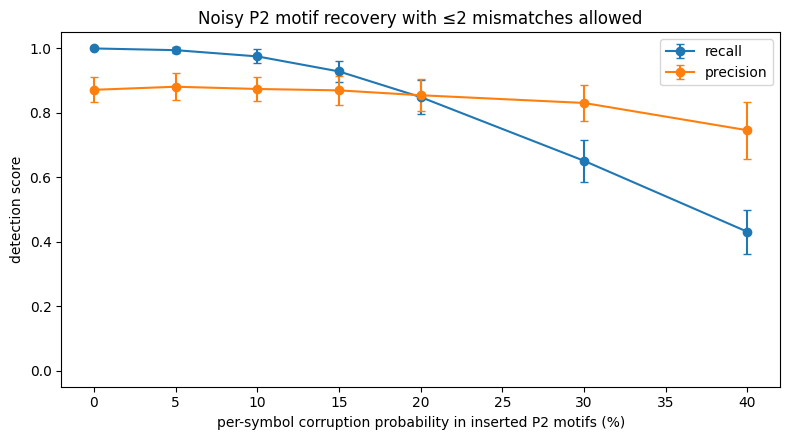

In [ ]:
def corrupt_motif(motif, corruption_rate, rng):
    out = motif.copy()
    for i in range(len(out)):
        if rng.random() < corruption_rate:
            choices = [s for s in UNIQUE_STATES if s != out[i]]
            out[i] = rng.choice(choices)
    return out


def hamming_distance(a, b):
    return sum(x != y for x, y in zip(a, b))


def noisy_motif_trial(
    corruption_rate,
    random_length=4000,
    insertions=50,
    allowed_mismatches=2,
    seed=0
):
    local_rng = np.random.default_rng(seed)
    motif = P2_LABELS.copy()
    alphabet = list(dict.fromkeys(P2_LABELS))
    stream = local_rng.choice(alphabet, size=random_length, replace=True).tolist()

    candidate_starts = np.arange(0, random_length - len(motif), len(motif) + 1)
    if len(candidate_starts) < insertions:
        raise ValueError("not enough non-overlapping insertion slots")
    starts = local_rng.choice(candidate_starts, size=insertions, replace=False)
    inserted = set(int(x) for x in starts)

    for pos in starts:
        stream[pos:pos+len(motif)] = corrupt_motif(motif, corruption_rate, local_rng)

    detected = set()
    for i in range(0, len(stream) - len(motif) + 1):
        window = stream[i:i+len(motif)]
        if hamming_distance(window, motif) <= allowed_mismatches:
            detected.add(i)

    tp = len(inserted & detected)
    fp = len(detected - inserted)
    fn = len(inserted - detected)
    precision = tp / (tp + fp) if (tp + fp) else 1.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    return precision, recall, fp


def noisy_motif_recovery_curve(
    corruption_levels=(0, .05, .10, .15, .20, .30, .40),
    trials=60,
    allowed_mismatches=2,
    seed=2026
):
    master = np.random.default_rng(seed)
    rows = []
    for corruption in corruption_levels:
        precision_vals, recall_vals, fp_vals = [], [], []
        for _ in range(trials):
            trial_seed = int(master.integers(0, 2**31 - 1))
            p, r, fp = noisy_motif_trial(
                corruption, allowed_mismatches=allowed_mismatches, seed=trial_seed
            )
            precision_vals.append(p)
            recall_vals.append(r)
            fp_vals.append(fp)
        rows.append({
            "corruption_rate": corruption,
            "mean_precision": float(np.mean(precision_vals)),
            "sd_precision": float(np.std(precision_vals, ddof=1)),
            "mean_recall": float(np.mean(recall_vals)),
            "sd_recall": float(np.std(recall_vals, ddof=1)),
            "mean_false_positive_windows": float(np.mean(fp_vals)),
        })
    return pd.DataFrame(rows)

motif_noise_df = noisy_motif_recovery_curve()
display(motif_noise_df)

plt.figure(figsize=(8, 4.5))
plt.errorbar(
    motif_noise_df["corruption_rate"] * 100,
    motif_noise_df["mean_recall"],
    yerr=motif_noise_df["sd_recall"], marker="o", capsize=3, label="recall"
)
plt.errorbar(
    motif_noise_df["corruption_rate"] * 100,
    motif_noise_df["mean_precision"],
    yerr=motif_noise_df["sd_precision"], marker="o", capsize=3, label="precision"
)
plt.xlabel("per-symbol corruption probability in inserted P2 motifs (%)")
plt.ylabel("detection score")
plt.ylim(-0.05, 1.05)
plt.title("Noisy P2 motif recovery with ≤2 mismatches allowed")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Export Results

In [ ]:
exports = {
    "P2_predictive_information_horizon.csv": horizon_df,
    "P3_dimensional_survival_null_summary.csv": p3_null_summary,
    "P3_dimensional_survival_null_trials.csv": p3_null_trials,
    "LDCT_monte_carlo_cut_robustness.csv": ldct_mc,
    "P2_mutation_detection_metrics.csv": mutation_summary,
    "Wilson_contradiction_aware_context_demo.csv": wilson_context_demo,
    "P2_noisy_motif_recovery.csv": motif_noise_df,
}

for filename, df in exports.items():
    df.to_csv(filename, index=False)
    print("saved", filename)

saved P2_predictive_information_horizon.csv
saved P3_dimensional_survival_null_summary.csv
saved P3_dimensional_survival_null_trials.csv
saved LDCT_monte_carlo_cut_robustness.csv
saved P2_mutation_detection_metrics.csv
saved Wilson_contradiction_aware_context_demo.csv
saved P2_noisy_motif_recovery.csv


## 8. Validation Checks

In [ ]:
# Canonical kernel was never rewritten.
assert CANONICAL_P2 == (
    (3, 3), (0, 0), (0, 1), (1, 2), (2, 1), (1, 0), (0, 0)
)
assert P2_CYCLE[-1] == "Delay(200)"

# Predictive-horizon result is finite and reaches zero uncertainty.
assert np.isfinite(horizon_df["conditional_entropy_bits"]).all()
assert horizon_df["zero_uncertainty"].any()

# Null-model outputs are complete.
assert len(p3_null_summary) == 6
assert p3_null_summary["p2_derived_rho"].notna().all()

# Monte Carlo run produced both strategies at all removal fractions.
assert set(ldct_mc["strategy"]) == {"random_nodes", "highest_degree_nodes"}

# Mutation metrics are bounded.
for col in ["precision", "recall", "f1"]:
    assert mutation_summary.loc[0, col] >= 0 and mutation_summary.loc[0, col] <= 1

# Context-C is rejected because of direction conflict in this toy rule.
row_c = wilson_context_demo.set_index("candidate").loc["context_C"]
assert bool(row_c["critical_conflict"])
assert not bool(row_c["accepted_under_toy_rule"])

# Noise curve is finite and bounded.
assert motif_noise_df[["mean_precision", "mean_recall"]].map(np.isfinite).all().all()
assert ((motif_noise_df["mean_precision"] >= 0) & (motif_noise_df["mean_precision"] <= 1)).all()
assert ((motif_noise_df["mean_recall"] >= 0) & (motif_noise_df["mean_recall"] <= 1)).all()

print("Analytical Upgrade Pack validation passed.")

Analytical Upgrade Pack validation passed.


## 9. Reading the Pack

The strongest direct result in this companion is the **Predictive Information Horizon**: it tests whether the observational ambiguity created by the repeated `0,0` coordinate disappears once finite temporal context is supplied. The remaining modules strengthen earlier demonstrations by adding null comparisons, repeated trials, event-level metrics, explicit contradiction handling, and controlled corruption.

These are computational properties of the simulation encodings used here. They should be cited as simulation or information-theoretic findings unless and until a separate physical experiment is designed to test a corresponding physical claim.

# 10. Creative Simulation Pack II

This section extends the analytical pack with seven deliberately different experiments.

**Canon boundary:** Tensor P2 remains exactly

`3,3 → 0,0 → 0,1 → 1,2 → 2,1 → 1,0 → 0,0 → Delay(200)`.

Tensor P3 remains the disclosed nested dimensional embedding context for P2, and the Echo Meridian remains the disclosed invariant coherence axis. The algorithms below use **simulation encodings, synthetic geometry, observer models, noise channels, graph/topology constructions, and audiovisual mappings**. These are not new QTET/QTL-Sphere definitions or constants.

Included here:
1. P2 Minimal-Memory Machine
2. P2 Doppelgänger Search
3. Blind Echo Meridian Recovery
4. P3 Vietoris–Rips Persistent-Homology Toy Model
5. Tensor Rosetta Stone
6. Recurrence Diagnostic Degradation Under Noise
7. Tensor Planetarium (audiovisual visualization)


## 10.1 P2 Minimal-Memory Machine

,memory_length,conditional_entropy_bits,predictive_contexts,deterministic_context_fraction,zero_uncertainty
0,0,2.75000,1,0.000000,False
1,1,0.25001,7,0.857143,False
2,2,0.00000,8,1.000000,True
3,3,0.00000,8,1.000000,True
4,4,0.00000,8,1.000000,True
5,5,0.00000,8,1.000000,True
6,6,0.00000,8,1.000000,True


Minimal immediately preceding observation count for zero next-state uncertainty: 2


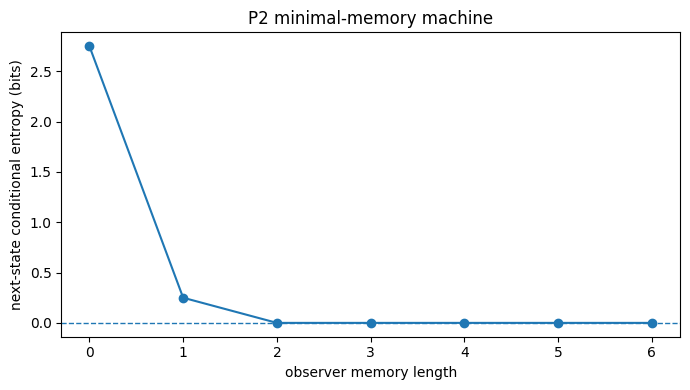

In [ ]:
from itertools import permutations, combinations
from collections import defaultdict
import gzip
from scipy.spatial.distance import squareform
from scipy.io.wavfile import write
from IPython.display import Audio


def conditional_entropy_k(seq, k):
    """H(next | previous k tokens); k=0 gives marginal H(next)."""
    if k == 0:
        counts = Counter(seq)
        n = len(seq)
        return -sum((v/n) * math.log2(v/n) for v in counts.values())
    joint = Counter()
    ctx = Counter()
    for i in range(k, len(seq)):
        history = tuple(seq[i-k:i])
        nxt = seq[i]
        joint[(history, nxt)] += 1
        ctx[history] += 1
    total = sum(joint.values())
    H = 0.0
    for (history, nxt), n in joint.items():
        p_joint = n / total
        p = n / ctx[history]
        H -= p_joint * math.log2(p)
    return H


def minimal_memory_machine(cycles=3000, max_k=6):
    seq = P2_CYCLE * cycles
    rows=[]
    for k in range(max_k+1):
        H = conditional_entropy_k(seq, k)
        if k == 0:
            n_contexts = 1
            deterministic_fraction = 0.0
        else:
            futures=defaultdict(Counter)
            for i in range(k, len(seq)):
                futures[tuple(seq[i-k:i])][seq[i]] += 1
            n_contexts=len(futures)
            deterministic_fraction=np.mean([len(c)==1 for c in futures.values()])
        rows.append({
            'memory_length':k,
            'conditional_entropy_bits':H,
            'predictive_contexts':n_contexts,
            'deterministic_context_fraction':deterministic_fraction,
            'zero_uncertainty':bool(np.isclose(H,0,atol=1e-12)),
        })
    df=pd.DataFrame(rows)
    return df

minimal_memory_df=minimal_memory_machine()
display(minimal_memory_df)
min_memory=int(minimal_memory_df.loc[minimal_memory_df.zero_uncertainty,'memory_length'].min())
print('Minimal immediately preceding observation count for zero next-state uncertainty:', min_memory)

plt.figure(figsize=(7,4))
plt.plot(minimal_memory_df.memory_length, minimal_memory_df.conditional_entropy_bits, marker='o')
plt.axhline(0,linestyle='--',linewidth=1)
plt.xlabel('observer memory length')
plt.ylabel('next-state conditional entropy (bits)')
plt.title('P2 minimal-memory machine')
plt.tight_layout(); plt.show()


The observer is not given a stage label for either `0,0`. The experiment asks how much immediate history is needed before the symbolic recurrent stream becomes deterministic to that observer.

## 10.2 P2 Doppelgänger Search

In [ ]:
P2_NO_DELAY = tuple(P2_LABELS)
P2_COORD_LOOKUP = {f'{x},{y}': np.array([x,y],dtype=float) for x,y in CANONICAL_P2}


def path_features(seq):
    coords=np.vstack([P2_COORD_LOOKUP[s] for s in seq])
    d=np.linalg.norm(np.diff(coords,axis=0),axis=1)
    # ordered turning cosines; duplicates/zero steps handled conservatively
    turns=[]
    vec=np.diff(coords,axis=0)
    for a,b in zip(vec[:-1],vec[1:]):
        na=np.linalg.norm(a); nb=np.linalg.norm(b)
        turns.append(0.0 if na==0 or nb==0 else float(np.dot(a,b)/(na*nb)))
    return {
        'start':seq[0], 'end':seq[-1],
        'path_length':float(d.sum()),
        'step_multiset':tuple(np.round(np.sort(d),8)),
        'turn_multiset':tuple(np.round(np.sort(turns),8)),
        'ordered_steps':tuple(np.round(d,8)),
        'signed_path_area':float(0.5*np.sum(coords[:,0]*np.roll(coords[:,1],-1)-coords[:,1]*np.roll(coords[:,0],-1))),
    }


def p2_doppelganger_search():
    target=path_features(P2_NO_DELAY)
    # Only 2520 unique permutations because 0,0 appears twice.
    candidates=set(permutations(P2_NO_DELAY))
    rows=[]
    for seq in candidates:
        if seq == P2_NO_DELAY:
            continue
        f=path_features(seq)
        score=0
        score += 1 if f['start']==target['start'] else 0
        score += 1 if f['end']==target['end'] else 0
        score += 1 if np.isclose(f['path_length'],target['path_length']) else 0
        score += 1 if f['step_multiset']==target['step_multiset'] else 0
        score += 1 if f['turn_multiset']==target['turn_multiset'] else 0
        ordered_match=sum(a==b for a,b in zip(f['ordered_steps'],target['ordered_steps']))
        rows.append({
            'similarity_score_simple_features':score,
            'ordered_step_matches_of_6':ordered_match,
            'candidate':' -> '.join(seq),
            'same_start':f['start']==target['start'],
            'same_end':f['end']==target['end'],
            'same_step_multiset':f['step_multiset']==target['step_multiset'],
            'same_turn_multiset':f['turn_multiset']==target['turn_multiset'],
            'signed_path_area':f['signed_path_area'],
            'target_signed_path_area':target['signed_path_area'],
        })
    df=pd.DataFrame(rows).sort_values(['similarity_score_simple_features','ordered_step_matches_of_6'],ascending=False).reset_index(drop=True)
    return df

doppel_df=p2_doppelganger_search()
display(doppel_df.head(12))
print('Total non-P2 permutations searched:',len(doppel_df))
print('Strongest simple-feature impostor:')
print(doppel_df.iloc[0].candidate)
print('Simple-feature score:',int(doppel_df.iloc[0].similarity_score_simple_features),'/ 5')
print('Ordered transition-length matches:',int(doppel_df.iloc[0].ordered_step_matches_of_6),'/ 6')
print('Canonical signed path area:',round(float(doppel_df.iloc[0].target_signed_path_area),4))
print('Impostor signed path area:',round(float(doppel_df.iloc[0].signed_path_area),4))
print('A direction-sensitive signed-area observable separates the strongest impostor despite its matched low-order distance statistics.')


,similarity_score_simple_features,ordered_step_matches_of_6,candidate,same_start,same_end,same_step_multiset,same_turn_multiset,signed_path_area,target_signed_path_area
0,5,6,"3,3 -> 0,0 -> 1,0 -> 2,1 -> 1,2 -> 0,1 -> 0,0",True,True,True,True,2.5,-2.5
1,3,2,"0,0 -> 1,0 -> 2,1 -> 1,2 -> 0,1 -> 0,0 -> 3,3",False,False,True,True,2.5,-2.5
2,3,2,"0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0 -> 0,0 -> 3,3",False,False,True,True,-2.5,-2.5
3,2,5,"3,3 -> 0,0 -> 2,1 -> 1,2 -> 0,1 -> 1,0 -> 0,0",True,True,False,False,1.5,-2.5
4,2,5,"3,3 -> 0,0 -> 1,0 -> 0,1 -> 1,2 -> 2,1 -> 0,0",True,True,False,False,-1.5,-2.5
5,2,5,"3,3 -> 0,0 -> 1,2 -> 2,1 -> 1,0 -> 0,1 -> 0,0",True,True,False,False,-1.5,-2.5
6,2,5,"3,3 -> 0,0 -> 0,1 -> 1,0 -> 2,1 -> 1,2 -> 0,0",True,True,False,False,1.5,-2.5
7,2,4,"3,3 -> 0,0 -> 0,1 -> 2,1 -> 1,2 -> 1,0 -> 0,0",True,True,False,False,-0.5,-2.5
8,2,4,"3,3 -> 0,0 -> 2,1 -> 1,2 -> 1,0 -> 0,1 -> 0,0",True,True,False,False,1.0,-2.5
9,2,4,"3,3 -> 0,0 -> 1,0 -> 0,1 -> 2,1 -> 1,2 -> 0,0",True,True,False,False,1.0,-2.5


Total non-P2 permutations searched: 2519
Strongest simple-feature impostor:
3,3 -> 0,0 -> 1,0 -> 2,1 -> 1,2 -> 0,1 -> 0,0
Simple-feature score: 5 / 5
Ordered transition-length matches: 6 / 6
Canonical signed path area: -2.5
Impostor signed path area: 2.5
A direction-sensitive signed-area observable separates the strongest impostor despite its matched low-order distance statistics.


This is an impostor search over the exact same multiset of seven observed coordinates. It asks which reordered paths can imitate several low-order geometric statistics and therefore which **ordered** measurement is needed to distinguish the canonical traversal from a near-match.

## 10.3 Blind Echo Meridian Recovery — Synthetic Hidden-Axis Experiment

,noise_sd,mean_axis_error_deg,sd_axis_error_deg,median_axis_error_deg
0,0.00,0.624762,0.360594,0.575600
1,0.25,0.652155,0.363332,0.604264
2,0.50,0.777744,0.410246,0.739378
3,0.75,0.978733,0.526259,0.905649
4,1.00,1.252112,0.689455,1.154730
5,1.25,1.501815,0.826779,1.503906
6,1.50,1.933692,0.921702,1.978327
7,1.75,2.459923,1.338016,2.494643
8,2.00,2.756609,1.581055,2.543248


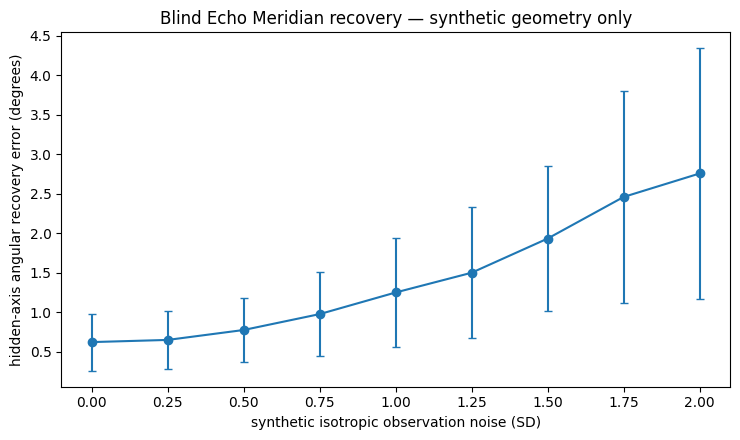

Example hidden axis: [ 0.1556 -0.2077  0.9657]
Example recovered axis: [ 0.1622 -0.2061  0.965 ]
Sign-invariant angular error (deg): 0.388


In [ ]:
def random_unit_vector(rng):
    v=rng.normal(size=3)
    return v/np.linalg.norm(v)


def orthogonal_basis(axis):
    # two perpendicular unit vectors
    seed=np.array([1.,0.,0.]) if abs(axis[0])<0.85 else np.array([0.,1.,0.])
    u=seed-axis*np.dot(seed,axis); u/=np.linalg.norm(u)
    v=np.cross(axis,u); v/=np.linalg.norm(v)
    return u,v


def hidden_axis_trial(noise=0.5, n_tracks=60, points_per_track=30, seed=0):
    lr=np.random.default_rng(seed)
    hidden=random_unit_vector(lr)
    u,v=orthogonal_basis(hidden)
    clouds=[]
    for _ in range(n_tracks):
        s=np.linspace(-3,3,points_per_track)
        # synthetic trajectory: dominant common axis + bounded transverse structure + noise
        phase=lr.uniform(0,2*np.pi)
        transverse=(0.25*np.sin(s+phase))[:,None]*u + (0.25*np.cos(0.8*s+phase))[:,None]*v
        pts=s[:,None]*hidden + transverse + lr.normal(scale=noise,size=(points_per_track,3))
        clouds.append(pts)
    X=np.vstack(clouds)
    X-=X.mean(axis=0)
    _,_,vt=np.linalg.svd(X,full_matrices=False)
    estimated=vt[0]
    c=np.clip(abs(np.dot(hidden,estimated)),0,1)  # axis sign is equivalent here
    angle=np.degrees(np.arccos(c))
    return angle,hidden,estimated,X


def blind_echo_meridian_recovery(noise_levels=np.linspace(0,2.0,9), trials=120):
    rows=[]
    for noise in noise_levels:
        vals=[]
        for t in range(trials):
            vals.append(hidden_axis_trial(noise=noise,seed=10000+t+int(noise*1000))[0])
        rows.append({'noise_sd':noise,'mean_axis_error_deg':np.mean(vals),'sd_axis_error_deg':np.std(vals,ddof=1),'median_axis_error_deg':np.median(vals)})
    return pd.DataFrame(rows)

meridian_recovery_df=blind_echo_meridian_recovery()
display(meridian_recovery_df)
plt.figure(figsize=(7.5,4.5))
plt.errorbar(meridian_recovery_df.noise_sd,meridian_recovery_df.mean_axis_error_deg,yerr=meridian_recovery_df.sd_axis_error_deg,marker='o',capsize=3)
plt.xlabel('synthetic isotropic observation noise (SD)')
plt.ylabel('hidden-axis angular recovery error (degrees)')
plt.title('Blind Echo Meridian recovery — synthetic geometry only')
plt.tight_layout(); plt.show()

angle,hidden,estimated,X=hidden_axis_trial(noise=0.8,seed=77)
print('Example hidden axis:',np.round(hidden,4))
print('Example recovered axis:',np.round(estimated,4))
print('Sign-invariant angular error (deg):',round(angle,3))


The estimator is deliberately not told the hidden axis. In this toy geometry it infers a common invariant direction from an ensemble of trajectories. This is a **blind-axis recoverability test**, not a physical derivation of the Echo Meridian equations.

## 10.4 P3 Vietoris–Rips Persistent-Homology Toy Model

,noise_sd,H0_intervals,H1_positive_persistence_intervals,max_H1_persistence,sum_H1_persistence
0,0.00,8,1,0.714553,0.714553
1,0.03,8,1,0.678100,0.678100
2,0.06,8,1,0.645560,0.645560
3,0.10,8,1,0.541476,0.541476
4,0.15,8,1,0.378487,0.378487
5,0.25,8,1,0.119667,0.119667


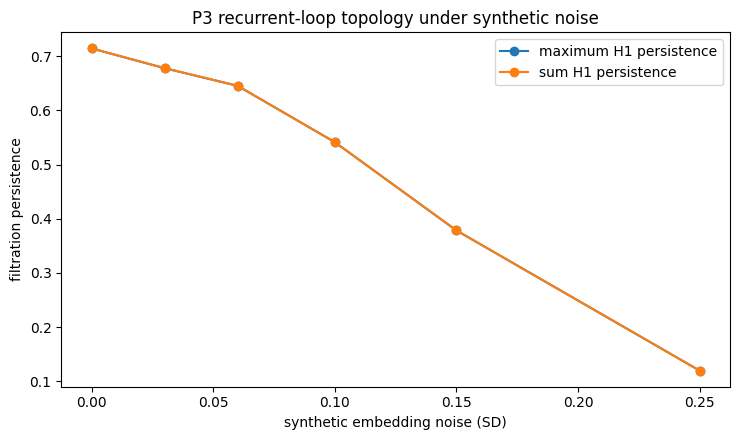

Clean H1 intervals (birth, death):
[(1.1696, 1.8841), (1.4544, 1.4544), (1.4689, 1.4689), (1.4886, 1.4886), (1.4896, 1.4896), (1.4914, 1.4914), (1.5084, 1.5084), (1.6003, 1.6003), (1.6599, 1.6599), (1.8523, 1.8523), (1.8631, 1.8631), (1.8841, 1.8841), (1.9023, 1.9023), (1.9067, 1.9067), (1.9107, 1.9107), (1.9151, 1.9151), (1.9918, 1.9918), (2.0249, 2.0249), (2.0384, 2.0384), (2.0541, 2.0541), (2.0692, 2.0692)]


In [ ]:
def p3_topology_embedding(dim=8, noise=0.0, seed=2026):
    """Simulation embedding: traversal position forms a recurrent loop; disclosed P2 coordinates modulate extra axes."""
    lr=np.random.default_rng(seed+dim)
    n=len(P2_CYCLE)
    theta=2*np.pi*np.arange(n)/n
    coords=np.array(list(CANONICAL_P2)+[(0,0)],dtype=float)  # Delay gets reference coordinate only for this visualization encoding
    feats=[np.cos(theta),np.sin(theta),0.20*coords[:,0],0.20*coords[:,1]]
    k=1
    while len(feats)<dim:
        feats.append(0.12*np.sin((k+1)*theta)+0.05*np.cos((k+2)*(coords[:,0]+1)))
        k+=1
    X=np.column_stack(feats[:dim])
    Q,_=np.linalg.qr(lr.normal(size=(dim,dim)))
    X=X@Q
    if noise:
        X=X+lr.normal(scale=noise,size=X.shape)
    return X


def vr_persistence_01(X):
    """Exact Z2 boundary-matrix reduction for VR filtration through triangles; returns H0/H1 intervals."""
    n=len(X)
    D=squareform(pdist(X))
    simplices=[]
    for i in range(n): simplices.append(((i,),0,0.0))
    for i,j in combinations(range(n),2): simplices.append(((i,j),1,float(D[i,j])))
    for i,j,k in combinations(range(n),3):
        f=max(D[i,j],D[i,k],D[j,k]); simplices.append(((i,j,k),2,float(f)))
    simplices.sort(key=lambda x:(x[2],x[1],x[0]))
    index={s[0]:idx for idx,s in enumerate(simplices)}
    boundaries=[]
    for verts,dim,f in simplices:
        if dim==0: boundaries.append(set())
        else: boundaries.append({index[tuple(v for q,v in enumerate(verts) if q!=r)] for r in range(len(verts))})
    reduced=[]; low_to_col={}; pair={}
    for j,col0 in enumerate(boundaries):
        col=set(col0)
        while col:
            low=max(col)
            if low in low_to_col: col ^= reduced[low_to_col[low]]
            else: break
        reduced.append(col)
        if col:
            low=max(col); low_to_col[low]=j; pair[low]=j
    intervals={0:[],1:[]}
    for i,(verts,dim,birth) in enumerate(simplices):
        if dim not in intervals: continue
        if len(reduced[i])==0:  # births a class
            if i in pair:
                death=simplices[pair[i]][2]
                intervals[dim].append((birth,death))
            else:
                intervals[dim].append((birth,np.inf))
    return intervals


def topology_noise_scan(noise_levels=(0,0.03,0.06,0.10,0.15,0.25), dim=8):
    rows=[]
    diagrams={}
    for noise in noise_levels:
        X=p3_topology_embedding(dim=dim,noise=noise,seed=2026)
        ints=vr_persistence_01(X); diagrams[noise]=ints
        h1=[d-b for b,d in ints[1] if np.isfinite(d)]
        h1_pos=[x for x in h1 if x>1e-10]
        rows.append({'noise_sd':noise,'H0_intervals':len(ints[0]),'H1_positive_persistence_intervals':len(h1_pos),'max_H1_persistence':max(h1_pos) if h1_pos else 0.0,'sum_H1_persistence':sum(h1_pos)})
    return pd.DataFrame(rows),diagrams

topology_df,topology_diagrams=topology_noise_scan()
display(topology_df)
plt.figure(figsize=(7.5,4.5))
plt.plot(topology_df.noise_sd,topology_df.max_H1_persistence,marker='o',label='maximum H1 persistence')
plt.plot(topology_df.noise_sd,topology_df.sum_H1_persistence,marker='o',label='sum H1 persistence')
plt.xlabel('synthetic embedding noise (SD)'); plt.ylabel('filtration persistence')
plt.title('P3 recurrent-loop topology under synthetic noise')
plt.legend(); plt.tight_layout(); plt.show()

base_h1=topology_diagrams[0][1]
print('Clean H1 intervals (birth, death):')
print([(round(b,4),round(d,4) if np.isfinite(d) else np.inf) for b,d in base_h1])


This uses an explicit **Vietoris–Rips toy embedding** and exact finite Z2 boundary reduction through triangles. The topological loop is a property of that simulation encoding of recurrence; it is not being asserted as a new canonical P3 topology.

## 10.5 Tensor Rosetta Stone — Recovering One Grammar Through Arbitrary Encodings

,letters,integers,pitches,binary,shapes,decoy_random_cycle,decoy_branching
letters,True,True,True,True,True,False,False
integers,True,True,True,True,True,False,False
pitches,True,True,True,True,True,False,False
binary,True,True,True,True,True,False,False
shapes,True,True,True,True,True,False,False
decoy_random_cycle,False,False,False,False,False,True,False
decoy_branching,False,False,False,False,False,False,True


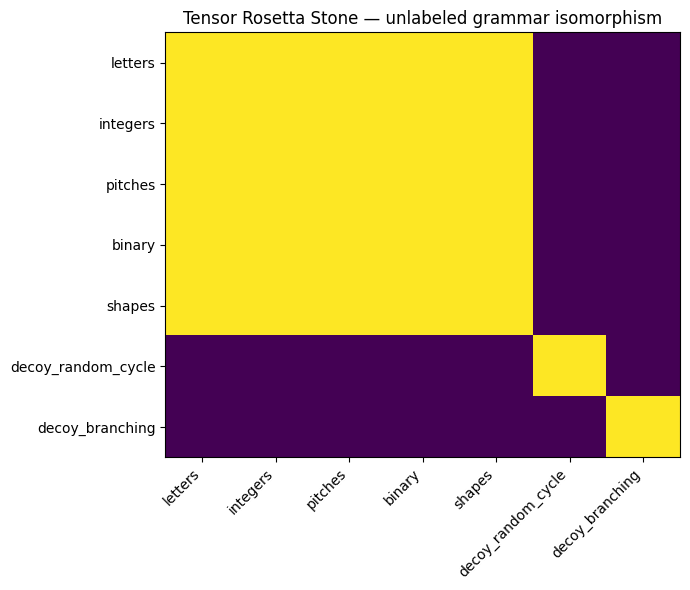

All five arbitrary P2 encodings mutually isomorphic: True
Any P2 encoding isomorphic to decoy_random_cycle: False
Any P2 encoding isomorphic to decoy_branching: False


In [ ]:
def first_order_grammar_graph(stream):
    """Directed transition grammar; node identities are arbitrary, topology is not."""
    G=nx.DiGraph()
    counts=Counter(stream)
    for node,n in counts.items():
        G.add_node(node, frequency=n)
    edge_counts=Counter(zip(stream[:-1],stream[1:]))
    for (a,b),n in edge_counts.items():
        G.add_edge(a,b, frequency=n)
    return G


def encode_cycle(mapping, cycles=40):
    return [mapping[s] for s in (P2_CYCLE*cycles)]


def rosetta_encodings(seed=2026):
    lr=np.random.default_rng(seed)
    base_states=list(dict.fromkeys(P2_CYCLE))
    enc={}
    enc['letters']={s:chr(65+i) for i,s in enumerate(base_states)}
    enc['integers']={s:int(v) for s,v in zip(base_states,lr.permutation(np.arange(101,101+len(base_states))))}
    enc['pitches']={s:int(v) for s,v in zip(base_states,[60,62,65,67,69,72,74])}
    enc['binary']={s:format(i,'03b') for i,s in enumerate(base_states)}
    enc['shapes']={s:v for s,v in zip(base_states,['circle','square','triangle','star','hex','diamond','ring'])}
    return enc


def tensor_rosetta_stone():
    enc=rosetta_encodings()
    graphs={name:first_order_grammar_graph(encode_cycle(mp)) for name,mp in enc.items()}
    # Decoy 1: simple 7-node cycle with a repeated boundary token (creates a self-loop under repetition).
    alphabet=list(enc['letters'].values())
    decoy1=[alphabet[i] for i in [0,1,2,3,4,5,6,0]]
    # Decoy 2: same seven-symbol vocabulary but a different branching location/topology.
    decoy2=[alphabet[i] for i in [0,1,2,1,3,4,5,6]]
    graphs['decoy_random_cycle']=first_order_grammar_graph(decoy1*40)
    graphs['decoy_branching']=first_order_grammar_graph(decoy2*40)
    names=list(graphs)
    mat=np.zeros((len(names),len(names)),dtype=bool)
    node_match=nx.algorithms.isomorphism.categorical_node_match('frequency',None)
    edge_match=nx.algorithms.isomorphism.categorical_edge_match('frequency',None)
    for i,a in enumerate(names):
        for j,b in enumerate(names):
            mat[i,j]=nx.is_isomorphic(graphs[a],graphs[b],node_match=node_match,edge_match=edge_match)
    return pd.DataFrame(mat,index=names,columns=names),graphs

rosetta_matrix,rosetta_graphs=tensor_rosetta_stone()
display(rosetta_matrix)

plt.figure(figsize=(7,6))
plt.imshow(rosetta_matrix.astype(int),aspect='auto',vmin=0,vmax=1)
plt.xticks(range(len(rosetta_matrix.columns)),rosetta_matrix.columns,rotation=45,ha='right')
plt.yticks(range(len(rosetta_matrix.index)),rosetta_matrix.index)
plt.title('Tensor Rosetta Stone — unlabeled grammar isomorphism')
plt.tight_layout(); plt.show()

p2_names=['letters','integers','pitches','binary','shapes']
print('All five arbitrary P2 encodings mutually isomorphic:',bool(rosetta_matrix.loc[p2_names,p2_names].to_numpy().all()))
print('Any P2 encoding isomorphic to decoy_random_cycle:',bool(rosetta_matrix.loc[p2_names,'decoy_random_cycle'].any()))
print('Any P2 encoding isomorphic to decoy_branching:',bool(rosetta_matrix.loc[p2_names,'decoy_branching'].any()))


This strips away the semantic labels entirely. The commonality being tested is transition grammar under arbitrary relabeling, not numerical resemblance between the encodings.

## 10.6 Recurrence Diagnostic Degradation Under Noise

,noise_probability,gzip_ratio,H1_bits,exact_cycle_rate,lag8_autocorrelation,fundamental_power_fraction
0,0.00,0.010155,0.250125,1.0000,1.000000,0.192277
1,0.05,0.041672,0.906741,0.6542,0.884009,0.175158
2,0.10,0.061522,1.321625,0.4304,0.774220,0.155638
3,0.15,0.078734,1.672644,0.2696,0.673103,0.140362
4,0.20,0.092034,1.928812,0.1689,0.582058,0.121261
5,0.25,0.103344,2.144509,0.0990,0.495067,0.108139
6,0.30,0.112352,2.310768,0.0597,0.420367,0.094339
7,0.35,0.119507,2.438651,0.0338,0.340662,0.077940


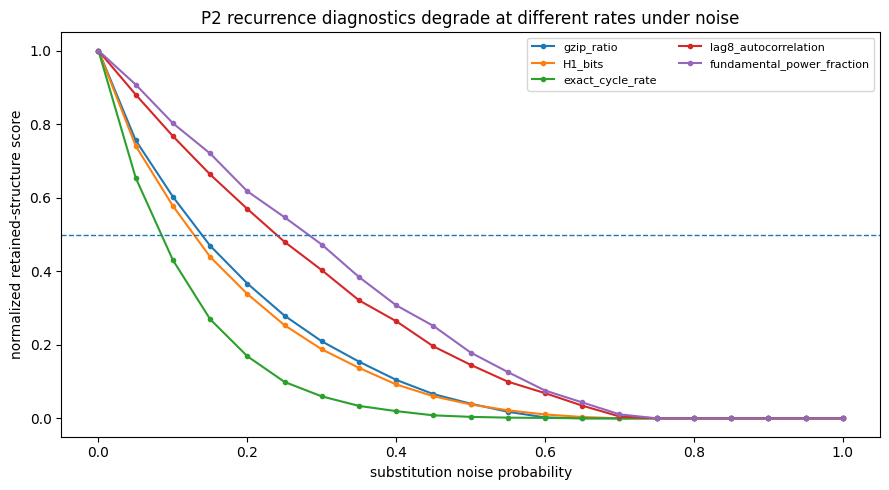

,diagnostic,first_noise_at_or_below_0.5
0,gzip_ratio,0.15
1,H1_bits,0.15
2,exact_cycle_rate,0.10
3,lag8_autocorrelation,0.25
4,fundamental_power_fraction,0.30


In [ ]:
STATE_IDS={s:i for i,s in enumerate(P2_CYCLE)}
CANONICAL_WINDOW=tuple(P2_CYCLE)


def corrupt_stream(seq, p, rng):
    out=[]
    alphabet=list(STATE_IDS)
    for s in seq:
        if rng.random()<p:
            choices=[x for x in alphabet if x!=s]
            out.append(rng.choice(choices))
        else: out.append(s)
    return out


def gzip_ratio_tokens(seq):
    raw='|'.join(seq).encode()
    return len(gzip.compress(raw))/len(raw)


def lag_cycle_autocorr(seq, lag=8):
    x=np.array([STATE_IDS[s] for s in seq],dtype=float)
    if len(x)<=lag:return np.nan
    a=x[:-lag]-x[:-lag].mean(); b=x[lag:]-x[lag:].mean()
    den=np.sqrt(np.dot(a,a)*np.dot(b,b))
    return 0.0 if den==0 else float(np.dot(a,b)/den)


def fundamental_power_fraction(seq, period=8):
    x=np.array([STATE_IDS[s] for s in seq],dtype=float); x=x-x.mean()
    power=np.abs(np.fft.rfft(x))**2
    freqs=np.fft.rfftfreq(len(x),d=1)
    target=1/period
    idx=np.argmin(abs(freqs-target))
    return float(power[idx]/power[1:].sum()) if power[1:].sum()>0 else 0.0


def exact_window_rate(seq):
    m=len(CANONICAL_WINDOW)
    return np.mean([tuple(seq[i:i+m])==CANONICAL_WINDOW for i in range(0,len(seq)-m+1,m)])


def recurrence_noise_scan(noise_levels=np.linspace(0,1,21),trials=40,cycles=250,seed=2026):
    lr=np.random.default_rng(seed); rows=[]
    base=P2_CYCLE*cycles
    for p in noise_levels:
        metrics=[]
        for _ in range(trials):
            s=corrupt_stream(base,p,lr)
            metrics.append((gzip_ratio_tokens(s),conditional_entropy_k(s,1),exact_window_rate(s),lag_cycle_autocorr(s),fundamental_power_fraction(s)))
        A=np.array(metrics,float)
        rows.append({'noise_probability':p,
                     'gzip_ratio':A[:,0].mean(),
                     'H1_bits':A[:,1].mean(),
                     'exact_cycle_rate':A[:,2].mean(),
                     'lag8_autocorrelation':A[:,3].mean(),
                     'fundamental_power_fraction':A[:,4].mean()})
    df=pd.DataFrame(rows)
    # Normalize each diagnostic so 1 = clean-structure-like and 0 = noise-endpoint-like.
    norm=pd.DataFrame({'noise_probability':df.noise_probability})
    for col,reverse in [('gzip_ratio',True),('H1_bits',True),('exact_cycle_rate',False),('lag8_autocorrelation',False),('fundamental_power_fraction',False)]:
        a=df[col].iloc[0]; b=df[col].iloc[-1]
        val=(df[col]-b)/(a-b) if not np.isclose(a,b) else np.ones(len(df))
        norm[col+'_structure_score']=np.clip(val,0,1)
    return df,norm

noise_diag_df,noise_structure_df=recurrence_noise_scan()
display(noise_diag_df.head(8))
plt.figure(figsize=(9,5))
for c in noise_structure_df.columns[1:]:
    plt.plot(noise_structure_df.noise_probability,noise_structure_df[c],marker='o',markersize=3,label=c.replace('_structure_score',''))
plt.axhline(0.5,linestyle='--',linewidth=1)
plt.xlabel('substitution noise probability')
plt.ylabel('normalized retained-structure score')
plt.title('P2 recurrence diagnostics degrade at different rates under noise')
plt.legend(ncol=2,fontsize=8); plt.tight_layout(); plt.show()

thresholds=[]
for c in noise_structure_df.columns[1:]:
    q=noise_structure_df.loc[noise_structure_df[c]<=0.5,'noise_probability']
    thresholds.append({'diagnostic':c.replace('_structure_score',''),'first_noise_at_or_below_0.5':float(q.min()) if len(q) else np.nan})
noise_threshold_df=pd.DataFrame(thresholds)
display(noise_threshold_df)


The five measurements are intentionally different: compressibility, first-order conditional entropy, exact motif survival, recurrence-lag autocorrelation, and spectral concentration. The useful question is whether they lose the recurrent signature at the same corruption level.

## 10.7 Tensor Planetarium — Audiovisual Visualization

### Portable Colab output folder
Generated files are written to `Path.cwd() / 'qtet_outputs'` (normally `/content/qtet_outputs` in Google Colab). The notebook creates the folder automatically, so it does not depend on the build-only `/mnt/data` path.


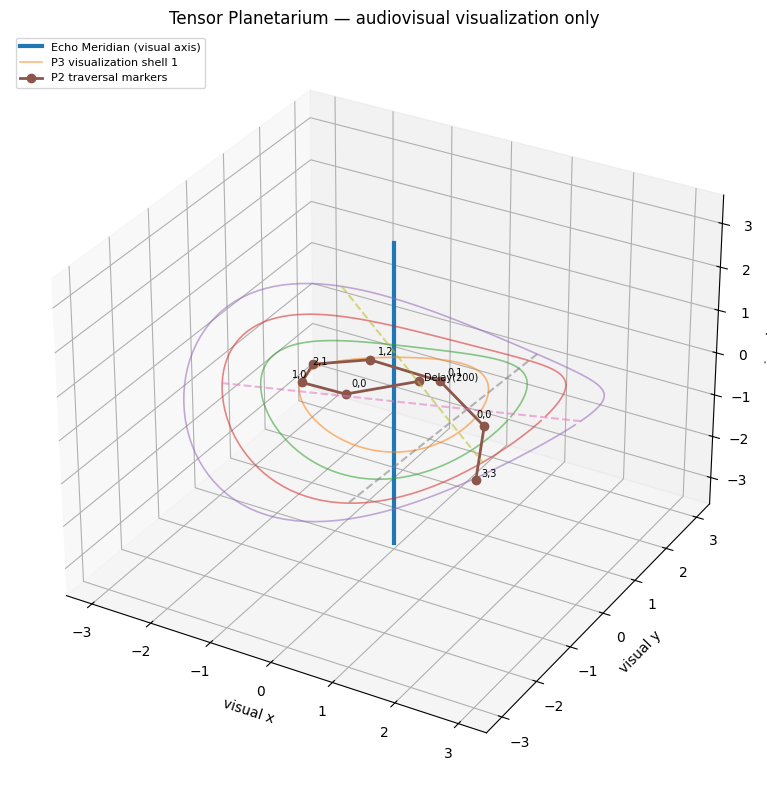

Saved planetarium image: /content/qtet_outputs/Tensor_Planetarium.png
Saved planetarium audio: /content/qtet_outputs/Tensor_Planetarium.wav


In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from pathlib import Path

# Portable output folder: /content/qtet_outputs in Colab, local qtet_outputs elsewhere.
OUTPUT_DIR = Path.cwd() / 'qtet_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)



def planetarium_geometry(shells=4, points_per_shell=120):
    theta=np.linspace(0,2*np.pi,points_per_shell,endpoint=False)
    records=[]
    for shell in range(1,shells+1):
        r=0.8+0.55*shell
        z_amp=0.18*shell
        x=r*np.cos(theta); y=r*np.sin(theta); z=z_amp*np.sin(2*theta+0.5*shell)
        records.append(np.column_stack([x,y,z]))
    # P2 event markers along a helical traversal; visualization mapping only.
    n=len(P2_CYCLE); tt=np.linspace(0,2*np.pi,n,endpoint=False)
    p2=np.column_stack([1.35*np.cos(tt),1.35*np.sin(tt),np.linspace(-1.4,1.4,n)])
    return records,p2


def render_tensor_planetarium(path=None):
    if path is None:
        path = OUTPUT_DIR / 'Tensor_Planetarium.png'
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    shells,p2=planetarium_geometry()
    fig=plt.figure(figsize=(8,8)); ax=fig.add_subplot(111,projection='3d')
    # Echo Meridian visual axis
    ax.plot([0,0],[0,0],[-3.5,3.5],linewidth=3,label='Echo Meridian (visual axis)')
    for i,S in enumerate(shells,1):
        ax.plot(S[:,0],S[:,1],S[:,2],alpha=0.55,linewidth=1.2,label=f'P3 visualization shell {i}' if i==1 else None)
    ax.plot(p2[:,0],p2[:,1],p2[:,2],marker='o',linewidth=2,label='P2 traversal markers')
    label_offsets=[(0.08,0.02,0.08),(-0.16,0.05,0.10),(0.06,0.10,0.08),(0.08,0.08,0.10),(0.05,-0.10,0.08),(-0.12,-0.08,0.10),(0.05,0.08,0.12),(0.12,-0.08,0.12)]
    for i,(x,y,z) in enumerate(p2):
        dx,dy,dz=label_offsets[i]
        ax.text(x+dx,y+dy,z+dz,P2_CYCLE[i],fontsize=7)
    # Synthetic long-distance links between shell points
    for a,b in [(0,70),(25,95),(45,110)]:
        A=shells[-1][a]; B=shells[-2][b%len(shells[-2])]
        ax.plot([A[0],B[0]],[A[1],B[1]],[A[2],B[2]],linestyle='--',alpha=0.55)
    ax.set_title('Tensor Planetarium — audiovisual visualization only')
    ax.set_xlabel('visual x'); ax.set_ylabel('visual y'); ax.set_zlabel('visual z')
    ax.legend(loc='upper left',fontsize=8); plt.tight_layout(); plt.savefig(path,dpi=180,bbox_inches='tight'); plt.show()
    return str(path)


def midi_freq(n): return 440.0*2**((n-69)/12)

def planetarium_audio(path=None,sample_rate=44100,beat_seconds=0.34,cycles=3):
    if path is None:
        path = OUTPUT_DIR / 'Tensor_Planetarium.wav'
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    # Sonification mapping only. Same state -> same base pitch; dimensions become octave-related voices.
    note_map={s:60+3*i for i,s in enumerate(dict.fromkeys(P2_CYCLE))}
    events=P2_CYCLE*cycles
    n_samples=int((len(events)+1)*beat_seconds*sample_rate)
    y=np.zeros(n_samples,float)
    for i,s in enumerate(events):
        start=int(i*beat_seconds*sample_rate); dur=int(0.30*sample_rate)
        t=np.arange(dur)/sample_rate
        base=note_map[s]
        tone=np.zeros(dur)
        for offset,amp in [(-12,0.28),(0,0.5),(12,0.22)]:
            tone += amp*np.sin(2*np.pi*midi_freq(base+offset)*t)
        env=np.minimum(1,t/0.02)*np.exp(-2.5*t)
        end=min(start+dur,n_samples); y[start:end]+=tone[:end-start]*env[:end-start]
    y/=max(np.max(np.abs(y)),1e-9); y*=0.85
    write(path,sample_rate,np.int16(y*32767))
    return str(path),y

planetarium_png=render_tensor_planetarium()
planetarium_wav,planetarium_wave=planetarium_audio()
print('Saved planetarium image:',planetarium_png)
print('Saved planetarium audio:',planetarium_wav)
display(Audio(planetarium_wave,rate=44100))


The planetarium intentionally combines previously disclosed elements in a **visual and auditory metaphor**. Shell radii, helix geometry, link placement, pitch choices, and audio envelopes are visualization controls only.

## 10.8 Export Creative Pack II Results

In [ ]:
creative_exports={
    'P2_minimal_memory_machine.csv':minimal_memory_df,
    'P2_doppelganger_search_top100.csv':doppel_df.head(100),
    'Echo_Meridian_blind_axis_recovery.csv':meridian_recovery_df,
    'P3_persistent_homology_noise_scan.csv':topology_df,
    'Tensor_Rosetta_Stone_isomorphism.csv':rosetta_matrix.astype(int),
    'P2_recurrence_noise_diagnostics.csv':noise_diag_df,
    'P2_recurrence_noise_structure_scores.csv':noise_structure_df,
    'P2_recurrence_noise_half_signal_thresholds.csv':noise_threshold_df,
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name,df in creative_exports.items():
    path = OUTPUT_DIR / name
    df.to_csv(path,index=True if 'Rosetta' in name else False)
    print('saved', path)


saved /content/qtet_outputs/P2_minimal_memory_machine.csv
saved /content/qtet_outputs/P2_doppelganger_search_top100.csv
saved /content/qtet_outputs/Echo_Meridian_blind_axis_recovery.csv
saved /content/qtet_outputs/P3_persistent_homology_noise_scan.csv
saved /content/qtet_outputs/Tensor_Rosetta_Stone_isomorphism.csv
saved /content/qtet_outputs/P2_recurrence_noise_diagnostics.csv
saved /content/qtet_outputs/P2_recurrence_noise_structure_scores.csv
saved /content/qtet_outputs/P2_recurrence_noise_half_signal_thresholds.csv


## 10.9 Validation

In [ ]:
# Canon lock and experiment sanity checks.
assert CANONICAL_P2 == ((3,3),(0,0),(0,1),(1,2),(2,1),(1,0),(0,0))
assert DELAY == 200
assert min_memory == 2
assert len(doppel_df) == 2519
assert meridian_recovery_df.mean_axis_error_deg.notna().all()
assert topology_df.max_H1_persistence.notna().all()
assert rosetta_matrix.loc[['letters','integers','pitches','binary','shapes'],['letters','integers','pitches','binary','shapes']].to_numpy().all()
assert not rosetta_matrix.loc[['letters','integers','pitches','binary','shapes'],'decoy_random_cycle'].any()
assert not rosetta_matrix.loc[['letters','integers','pitches','binary','shapes'],'decoy_branching'].any()
assert len(noise_diag_df) == 21
print('Creative Simulation Pack II validation passed.')


Creative Simulation Pack II validation passed.


## 10.10 Reading the New Pack

These experiments answer different questions:

- **Minimal-Memory Machine:** how much immediate observation history removes next-state ambiguity?
- **Doppelgänger Search:** how easily can reordered state paths mimic low-order geometric statistics?
- **Blind Echo Meridian Recovery:** can a hidden common axis be inferred from synthetic trajectory ensembles without revealing it to the estimator?
- **Persistent Homology:** does a deliberately recurrent P3 toy embedding retain a loop-like topological feature under synthetic noise?
- **Tensor Rosetta Stone:** can arbitrary relabelings be recognized as the same transition grammar?
- **Noise Degradation:** do different recurrence diagnostics fail at the same or different noise levels?
- **Tensor Planetarium:** what does the disclosed architecture look and sound like when translated into one audiovisual visualization?

All outputs in this section are simulation-derived. None of the added encoding formulas, thresholds, geometries, statistics, or audio mappings are canonical QTET/QTL-Sphere definitions.


# Creative Simulation Pack III — Hidden Observers, Tomography & Warped Time

This pack extends the existing notebook with ten new experiments that probe **observability, recoverability, representation, and synthetic environmental expression** without altering the fixed Tensor P2 kernel.

**Canon boundary:** Tensor P2 remains exactly

`3,3 → 0,0 → 0,1 → 1,2 → 2,1 → 1,0 → 0,0 → Delay(200)`.

Tensor P3 remains the nested dimensional embedding form of P2 while preserving P2 invariance. Echo Meridian, QRTM, and Wilson terminology are used only where already disclosed. Every projection formula, phase channel, braid geometry, threshold, classifier, environmental forcing, and observation channel introduced below is explicitly a **simulation or visualization construct**, not a new canonical definition.

New experiments:
1. Unknown-Phase Synchronization
2. Finite Predictive-State Reconstruction
3. P3 Tomography from 2-D Shadows
4. Tensor Braid Visualization
5. QRTM Phase-Torus / Phase-Slip Toy Model
6. Wilson Ambiguity Tournament
7. Observer Resolution Limits
8. Counterfactual Twin Environment Lab
9. Temporal-Stretch Recognition with DTW
10. P2 Information Telescope

In [ ]:
from collections import defaultdict
from pathlib import Path
from scipy.spatial.distance import pdist, squareform

# Reuse the portable output folder from Pack II; create it if this section is run alone.
if 'OUTPUT_DIR' not in globals():
    OUTPUT_DIR = Path.cwd() / 'qtet_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PACK3_SEED = 314159

# Canon lock at the Pack III boundary.
assert CANONICAL_P2 == ((3,3),(0,0),(0,1),(1,2),(2,1),(1,0),(0,0))
assert DELAY == 200
assert P2_CYCLE == ['3,3','0,0','0,1','1,2','2,1','1,0','0,0','Delay(200)']
print('Pack III canon lock passed.')

Pack III canon lock passed.


## 11.1 Unknown-Phase Synchronization

An observer is dropped into the recurrent P2+Delay stream at an unknown phase. The experiment asks how many consecutive observations are needed to identify the observer's exact position in the eight-event recurrence. We then erase observations at random and measure how synchronization degrades.

This is an **observability experiment**. It does not assign a new physical meaning to phase.

,erasure_rate,context_length,unique_phase_probability,mean_candidate_phases
0,0.00,1,0.754667,1.245333
1,0.00,2,1.000000,1.000000
2,0.00,3,1.000000,1.000000
3,0.00,4,1.000000,1.000000
4,0.00,5,1.000000,1.000000
5,0.00,6,1.000000,1.000000
6,0.00,7,1.000000,1.000000
7,0.00,8,1.000000,1.000000
8,0.10,1,0.679667,1.922333
9,0.10,2,0.942333,1.141667


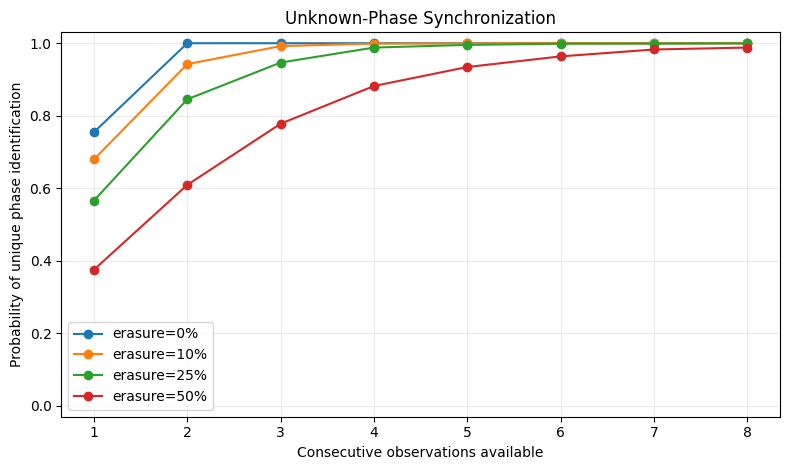

Exact observation, one state: 0.7546666666666667
Exact observation, two states: 1.0


In [ ]:
def pack3_phase_candidates(observation_window):
    L = len(P2_CYCLE)
    candidates = []
    for phase in range(L):
        ok = True
        for j, observed in enumerate(observation_window):
            if observed is not None and P2_CYCLE[(phase + j) % L] != observed:
                ok = False
                break
        if ok:
            candidates.append(phase)
    return candidates


def pack3_phase_sync_curve(max_context=8, erasure_rates=(0.0, 0.10, 0.25, 0.50), trials=3000, seed=PACK3_SEED):
    local_rng = np.random.default_rng(seed)
    L = len(P2_CYCLE)
    rows = []
    for erasure_rate in erasure_rates:
        for context_length in range(1, max_context + 1):
            unique_count = 0
            candidate_counts = []
            for _ in range(trials):
                phase = int(local_rng.integers(L))
                obs = [P2_CYCLE[(phase + j) % L] for j in range(context_length)]
                obs = [None if local_rng.random() < erasure_rate else x for x in obs]
                candidates = pack3_phase_candidates(obs)
                candidate_counts.append(len(candidates))
                unique_count += (len(candidates) == 1)
            rows.append({
                'erasure_rate': erasure_rate,
                'context_length': context_length,
                'unique_phase_probability': unique_count / trials,
                'mean_candidate_phases': float(np.mean(candidate_counts)),
            })
    return pd.DataFrame(rows)

phase_sync_df = pack3_phase_sync_curve()
display(phase_sync_df)

fig, ax = plt.subplots(figsize=(8, 4.8))
for erasure_rate, group in phase_sync_df.groupby('erasure_rate'):
    ax.plot(group['context_length'], group['unique_phase_probability'], marker='o', label=f'erasure={erasure_rate:.0%}')
ax.set_xlabel('Consecutive observations available')
ax.set_ylabel('Probability of unique phase identification')
ax.set_ylim(-0.03, 1.03)
ax.set_title('Unknown-Phase Synchronization')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
phase_sync_png = OUTPUT_DIR / 'P2_unknown_phase_synchronization.png'
plt.savefig(phase_sync_png, dpi=170, bbox_inches='tight')
plt.show()

exact_phase = phase_sync_df[phase_sync_df['erasure_rate'] == 0]
print('Exact observation, one state:', float(exact_phase.loc[exact_phase.context_length == 1, 'unique_phase_probability'].iloc[0]))
print('Exact observation, two states:', float(exact_phase.loc[exact_phase.context_length == 2, 'unique_phase_probability'].iloc[0]))

### Reading the phase result
A single exact observation cannot always distinguish the two traversal occurrences of `0,0`. Consecutive relational context can. The erasure curves quantify how quickly that phase information is lost when observations are missing.

## 11.2 Finite Predictive-State Reconstruction

Here histories are grouped by the distributions of short future blocks that follow them. This is a finite-history **predictive-equivalence construction** inspired by causal-state analysis; it is not asserted as a new canonical operator.

,history_length,observed_contexts,predictive_equivalence_classes,weighted_future_block_entropy_bits
0,1,7,7,0.249961
1,2,8,8,0.000000
2,3,8,8,0.000000


,history_length,context,predictive_class,future_block_entropy_bits,support,distinct_future_blocks
0,1,"3,3",0,-0.0,800,1
1,1,"0,0",1,1.0,1599,2
2,1,"0,1",2,-0.0,800,1
3,1,"1,2",3,-0.0,800,1
4,1,"2,1",4,-0.0,800,1
5,1,"1,0",5,-0.0,799,1
6,1,Delay(200),6,-0.0,799,1
7,2,"3,3 | 0,0",0,-0.0,800,1
8,2,"0,0 | 0,1",1,-0.0,800,1
9,2,"0,1 | 1,2",2,-0.0,800,1


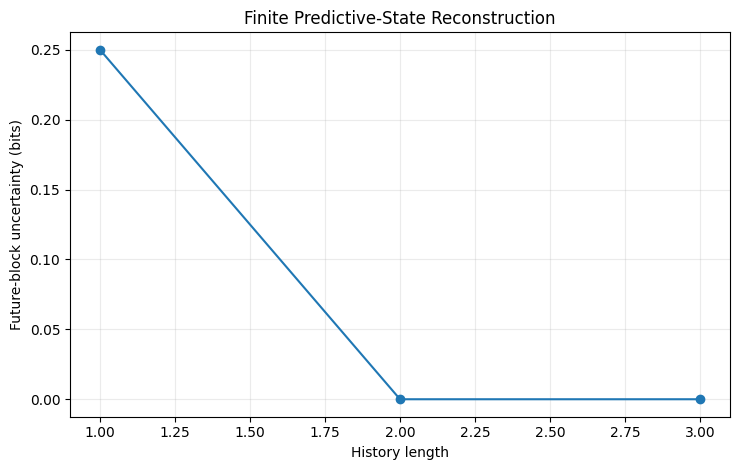

In [ ]:
def pack3_future_block_partition(history_length=1, future_length=3, cycles=800):
    seq = P2_CYCLE * int(cycles)
    future_counts = defaultdict(Counter)
    context_counts = Counter()

    for i in range(history_length, len(seq) - future_length + 1):
        context = tuple(seq[i-history_length:i])
        future = tuple(seq[i:i+future_length])
        future_counts[context][future] += 1
        context_counts[context] += 1

    signature_to_class = {}
    rows = []
    for context, counts in future_counts.items():
        total = sum(counts.values())
        signature = tuple(sorted((future, n / total) for future, n in counts.items()))
        if signature not in signature_to_class:
            signature_to_class[signature] = len(signature_to_class)
        H = -sum((n/total) * math.log2(n/total) for n in counts.values())
        rows.append({
            'history_length': history_length,
            'context': ' | '.join(context),
            'predictive_class': signature_to_class[signature],
            'future_block_entropy_bits': H,
            'support': total,
            'distinct_future_blocks': len(counts),
        })
    return pd.DataFrame(rows).sort_values(['predictive_class', 'context']).reset_index(drop=True)

predictive_contexts = pd.concat(
    [pack3_future_block_partition(history_length=h, future_length=3) for h in (1, 2, 3)],
    ignore_index=True
)

summary_rows = []
for h, group in predictive_contexts.groupby('history_length'):
    weighted_H = np.average(group['future_block_entropy_bits'], weights=group['support'])
    summary_rows.append({
        'history_length': h,
        'observed_contexts': len(group),
        'predictive_equivalence_classes': group['predictive_class'].nunique(),
        'weighted_future_block_entropy_bits': weighted_H,
    })
predictive_summary_df = pd.DataFrame(summary_rows)

display(predictive_summary_df)
display(predictive_contexts[predictive_contexts['history_length'].isin([1, 2])])

fig, ax1 = plt.subplots(figsize=(7.5, 4.8))
ax1.plot(predictive_summary_df['history_length'], predictive_summary_df['weighted_future_block_entropy_bits'], marker='o')
ax1.set_xlabel('History length')
ax1.set_ylabel('Future-block uncertainty (bits)')
ax1.set_title('Finite Predictive-State Reconstruction')
ax1.grid(alpha=0.25)
plt.tight_layout()
predictive_png = OUTPUT_DIR / 'P2_predictive_state_reconstruction.png'
plt.savefig(predictive_png, dpi=170, bbox_inches='tight')
plt.show()

## 11.3 P3 Tomography from 2-D Shadows

A simulation-only high-dimensional embedding of the exact seven P2 traversal events is hidden. The observer receives random 2-D orthogonal projections and estimates the original pairwise geometry from the collection of shadows.

The auxiliary coordinates and random-projection estimator are visualization mathematics only; they do **not** define Tensor P3.

,num_2d_projections,mean_distance_rank_correlation,sd_distance_rank_correlation,mean_relative_distance_error
0,1,0.385649,0.291221,0.645880
1,2,0.538734,0.222424,0.457864
2,4,0.691656,0.181934,0.323145
3,8,0.806104,0.086398,0.225724
4,16,0.881932,0.056247,0.155437
5,32,0.934481,0.028597,0.108971
6,64,0.962581,0.020452,0.077731


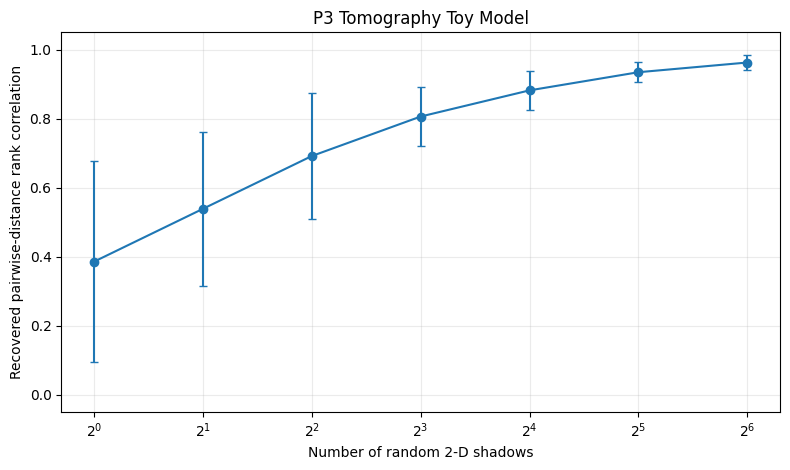

In [ ]:
def pack3_p3_highdim_embedding(dim=8):
    xy = np.asarray(CANONICAL_P2, dtype=float)
    step = np.arange(len(xy), dtype=float)
    features = [xy[:, 0], xy[:, 1]]
    k = 1
    while len(features) < dim:
        features.append(
            np.sin((k + 1) * (step + 1) / 3.0)
            + 0.25 * np.cos(k * (xy[:, 0] + 1))
            + 0.15 * np.sin((k + 2) * (xy[:, 1] + 1))
        )
        k += 1
    X = np.column_stack(features[:dim])
    return X - X.mean(axis=0, keepdims=True)


def pack3_tomography_trial(num_projections, dim=8, seed=0):
    local_rng = np.random.default_rng(seed)
    X = pack3_p3_highdim_embedding(dim)
    true_sq = squareform(pdist(X, metric='sqeuclidean'))
    estimated_sq = np.zeros_like(true_sq)

    for _ in range(num_projections):
        random_basis = local_rng.normal(size=(dim, 2))
        Q, _ = np.linalg.qr(random_basis)
        shadow = X @ Q[:, :2]
        projected_sq = squareform(pdist(shadow, metric='sqeuclidean'))
        estimated_sq += projected_sq * (dim / 2.0)

    estimated_sq /= num_projections
    upper = np.triu_indices(len(X), 1)
    true_vals = true_sq[upper]
    est_vals = estimated_sq[upper]
    rho = stats.spearmanr(true_vals, est_vals).statistic
    relative_mae = np.mean(np.abs(est_vals - true_vals) / (true_vals + 1e-12))
    return float(rho), float(relative_mae)


def pack3_tomography_sweep(projection_counts=(1,2,4,8,16,32,64), trials=80, dim=8):
    rows = []
    for K in projection_counts:
        values = [pack3_tomography_trial(K, dim=dim, seed=1000 + i) for i in range(trials)]
        rho = np.array([v[0] for v in values])
        err = np.array([v[1] for v in values])
        rows.append({
            'num_2d_projections': K,
            'mean_distance_rank_correlation': rho.mean(),
            'sd_distance_rank_correlation': rho.std(ddof=1),
            'mean_relative_distance_error': err.mean(),
        })
    return pd.DataFrame(rows)

tomography_df = pack3_tomography_sweep()
display(tomography_df)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.errorbar(
    tomography_df['num_2d_projections'],
    tomography_df['mean_distance_rank_correlation'],
    yerr=tomography_df['sd_distance_rank_correlation'],
    marker='o', capsize=3
)
ax.set_xscale('log', base=2)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel('Number of random 2-D shadows')
ax.set_ylabel('Recovered pairwise-distance rank correlation')
ax.set_title('P3 Tomography Toy Model')
ax.grid(alpha=0.25)
plt.tight_layout()
tomography_png = OUTPUT_DIR / 'P3_tomography_recovery.png'
plt.savefig(tomography_png, dpi=170, bbox_inches='tight')
plt.show()

## 11.4 Tensor Braid Visualization

Four visualization strands carry the same recurrent event driver while being given different geometric phase offsets. We count strand crossings in one projection and check that simply renaming the strands leaves the unordered crossing signature unchanged.

This is an artistic/topological visualization mapping, not a canonical Tensor P3 braid rule.

,Axis 1,Axis 2,Axis 3,Axis 4
Axis 1,0,4,6,4
Axis 2,4,0,4,4
Axis 3,6,4,0,6
Axis 4,4,4,6,0


Crossing signature: [4, 4, 4, 4, 6, 6]
Unchanged after strand relabeling: True


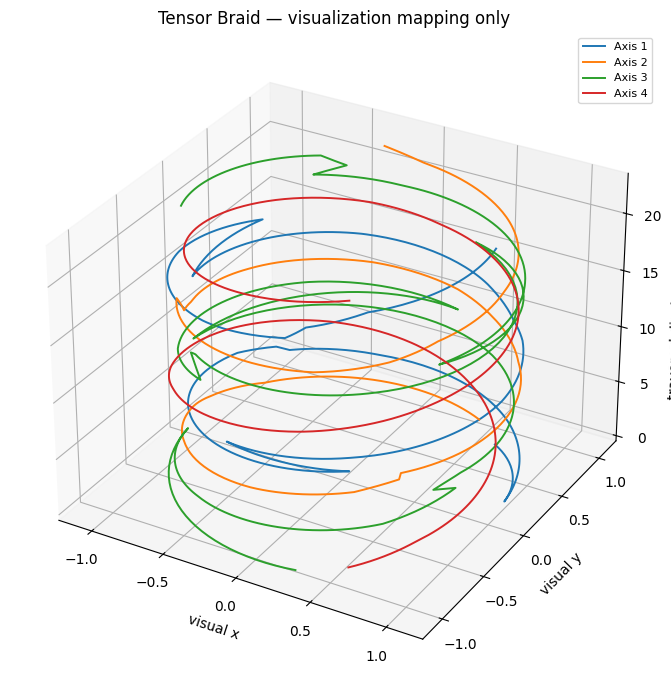

In [ ]:
def pack3_braid_geometry(n_strands=4, cycles=3, points_per_event=30):
    # Numerical driver is a visualization map only; Delay receives a separate display code.
    event_signal = np.array([6, 0, 1, 3, 3, 1, 0, 2.0], dtype=float)
    values = np.tile(event_signal, cycles)
    event_t = np.arange(len(values), dtype=float)
    fine_t = np.linspace(0, len(values) - 1, (len(values) - 1) * points_per_event + 1)
    signal = np.interp(fine_t, event_t, values)

    strands = []
    for axis in range(n_strands):
        base = 2 * np.pi * axis / n_strands
        theta = base + 0.55 * fine_t + 0.22 * ((-1) ** axis) * (signal - 2.0) + 0.08 * axis * signal
        radius = 1.0 + 0.08 * np.sin(0.7 * fine_t + axis)
        x = radius * np.cos(theta)
        y = radius * np.sin(theta)
        z = fine_t
        strands.append(np.column_stack([x, y, z]))
    return strands


def pack3_crossing_matrix(strands):
    n = len(strands)
    matrix = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(i + 1, n):
            diff = strands[i][:, 0] - strands[j][:, 0]
            signs = np.sign(diff)
            signs[signs == 0] = 1
            crossings = int(np.sum(signs[1:] != signs[:-1]))
            matrix[i, j] = matrix[j, i] = crossings
    return matrix

braid_strands = pack3_braid_geometry()
braid_matrix = pack3_crossing_matrix(braid_strands)
braid_crossing_df = pd.DataFrame(
    braid_matrix,
    index=[f'Axis {i+1}' for i in range(len(braid_strands))],
    columns=[f'Axis {i+1}' for i in range(len(braid_strands))]
)
display(braid_crossing_df)

crossing_signature = sorted(braid_matrix[np.triu_indices(len(braid_strands), 1)].tolist())
permutation = [2, 0, 3, 1]
permuted = [braid_strands[i] for i in permutation]
permuted_matrix = pack3_crossing_matrix(permuted)
permuted_signature = sorted(permuted_matrix[np.triu_indices(len(permuted), 1)].tolist())
print('Crossing signature:', crossing_signature)
print('Unchanged after strand relabeling:', crossing_signature == permuted_signature)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')
for i, strand in enumerate(braid_strands, 1):
    ax.plot(strand[:, 0], strand[:, 1], strand[:, 2], linewidth=1.4, label=f'Axis {i}')
ax.set_xlabel('visual x')
ax.set_ylabel('visual y')
ax.set_zlabel('traversal display coordinate')
ax.set_title('Tensor Braid — visualization mapping only')
ax.legend(fontsize=8)
plt.tight_layout()
braid_png = OUTPUT_DIR / 'Tensor_Braid_visualization.png'
plt.savefig(braid_png, dpi=180, bbox_inches='tight')
plt.show()

## 11.5 QRTM Phase Torus / Phase-Slip Toy Model

Two bounded synthetic oscillatory phases are mapped to a torus. At a selected point a controlled phase slip is injected, and a simple detector tests whether the discontinuity is visible in wrapped phase difference.

The oscillator equations, noise, slip sizes, and detector threshold are simulation controls only. They do not redefine QRTM admissibility or canonical threshold rules.

,noise_level,injected_slip_radians,detection_probability,false_positive_probability
0,0.00,0.00,0.0,0.0
1,0.00,0.40,0.0,0.0
2,0.00,0.60,0.0,0.0
3,0.00,0.80,1.0,0.0
4,0.00,1.00,1.0,0.0
5,0.00,1.40,1.0,0.0
6,0.00,2.00,1.0,0.0
7,0.00,3.14,1.0,0.0
8,0.05,0.00,0.0,0.0
9,0.05,0.40,0.0,0.0


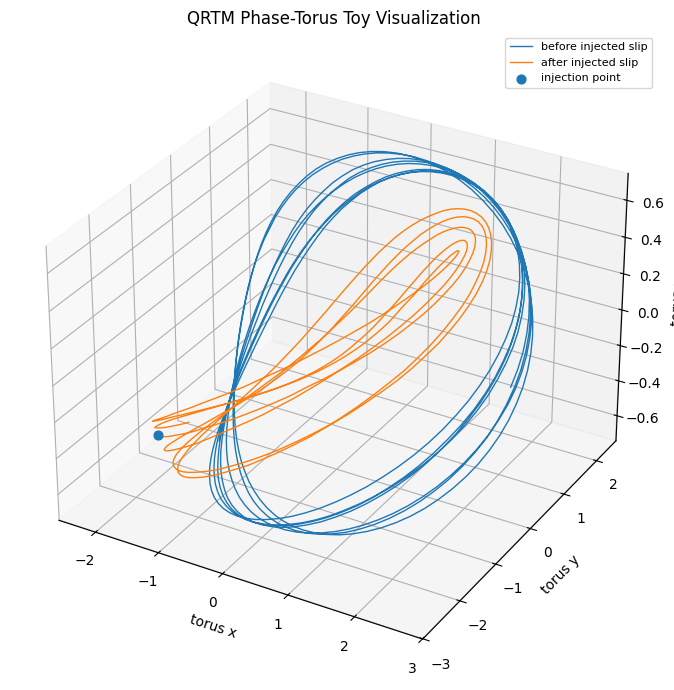

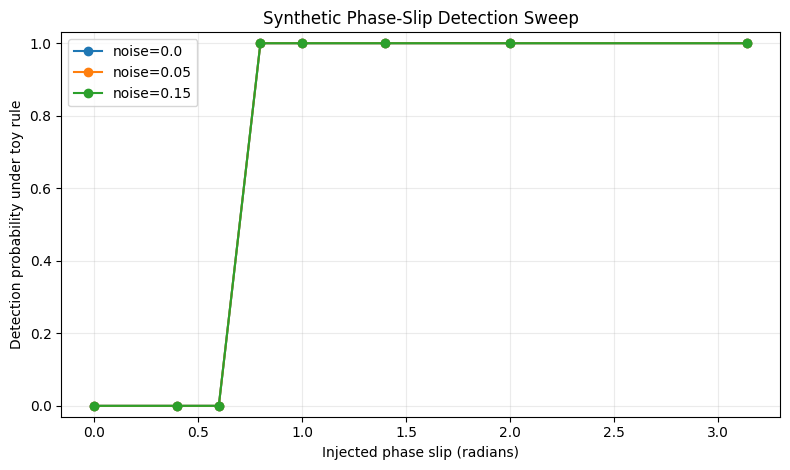

In [ ]:
def pack3_phase_torus_trial(slip_size=1.2, noise=0.05, seed=0, n=1000, slip_at=600, threshold=0.65):
    local_rng = np.random.default_rng(seed)
    t = np.arange(n, dtype=float)
    theta_1 = 0.08 * t + np.cumsum(local_rng.normal(0, noise, size=n)) * 0.03
    theta_2 = 0.08 * t + 0.35 * np.sin(0.015 * t) + np.cumsum(local_rng.normal(0, noise, size=n)) * 0.03
    theta_2[slip_at:] += slip_size

    phase_difference = np.unwrap(np.angle(np.exp(1j * (theta_1 - theta_2))))
    jumps = np.abs(np.diff(phase_difference))
    detected = bool(np.any(jumps[slip_at-3:slip_at+4] > threshold))
    false_positive = bool(np.any(jumps[:slip_at-20] > threshold))
    return detected, false_positive, theta_1, theta_2, phase_difference


def pack3_phase_slip_scan(slip_sizes=(0,0.4,0.6,0.8,1.0,1.4,2.0,3.14), noise_levels=(0.0,0.05,0.15), trials=120):
    rows = []
    for noise in noise_levels:
        for slip in slip_sizes:
            outcomes = [pack3_phase_torus_trial(slip, noise, seed=9000+i)[:2] for i in range(trials)]
            rows.append({
                'noise_level': noise,
                'injected_slip_radians': slip,
                'detection_probability': np.mean([x[0] for x in outcomes]),
                'false_positive_probability': np.mean([x[1] for x in outcomes]),
            })
    return pd.DataFrame(rows)

phase_torus_df = pack3_phase_slip_scan()
display(phase_torus_df)

# One illustrative torus trajectory.
_, _, th1, th2, _ = pack3_phase_torus_trial(slip_size=1.4, noise=0.05, seed=7)
R, r = 2.0, 0.65
x_torus = (R + r * np.cos(th2)) * np.cos(th1)
y_torus = (R + r * np.cos(th2)) * np.sin(th1)
z_torus = r * np.sin(th2)
slip_at = 600

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x_torus[:slip_at], y_torus[:slip_at], z_torus[:slip_at], linewidth=1.0, label='before injected slip')
ax.plot(x_torus[slip_at:], y_torus[slip_at:], z_torus[slip_at:], linewidth=1.0, label='after injected slip')
ax.scatter([x_torus[slip_at]], [y_torus[slip_at]], [z_torus[slip_at]], s=40, label='injection point')
ax.set_title('QRTM Phase-Torus Toy Visualization')
ax.set_xlabel('torus x')
ax.set_ylabel('torus y')
ax.set_zlabel('torus z')
ax.legend(fontsize=8)
plt.tight_layout()
phase_torus_png = OUTPUT_DIR / 'QRTM_phase_torus.png'
plt.savefig(phase_torus_png, dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
for noise, group in phase_torus_df.groupby('noise_level'):
    ax.plot(group['injected_slip_radians'], group['detection_probability'], marker='o', label=f'noise={noise}')
ax.set_xlabel('Injected phase slip (radians)')
ax.set_ylabel('Detection probability under toy rule')
ax.set_ylim(-0.03, 1.03)
ax.set_title('Synthetic Phase-Slip Detection Sweep')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
phase_slip_png = OUTPUT_DIR / 'QRTM_phase_slip_detection.png'
plt.savefig(phase_slip_png, dpi=170, bbox_inches='tight')
plt.show()

## 11.6 Wilson Ambiguity Tournament

Synthetic evidence arrives one degree of freedom at a time. Candidate contexts remain alive unless a revealed degree of freedom directly contradicts them. Support and coverage are displayed separately, so a partial but non-contradictory context is not confused with a fully supported context.

This is a **toy context-selection experiment around disclosed Wilson context accumulation**, not a canonical Wilson decision algorithm.

,round,evidence_revealed,candidate,active,support,contradictions,coverage
0,1,motion=left,A_exact,True,1,0,1.000000
1,1,motion=left,B_direction_conflict,False,0,1,1.000000
2,1,motion=left,C_object_conflict,True,1,0,1.000000
3,1,motion=left,D_multi_conflict,True,1,0,1.000000
4,1,motion=left,E_late_conflict,True,1,0,1.000000
5,1,motion=left,F_partial_compatible,True,1,0,1.000000
6,2,object=vehicle,A_exact,True,2,0,1.000000
7,2,object=vehicle,B_direction_conflict,False,1,1,1.000000
8,2,object=vehicle,C_object_conflict,False,1,1,1.000000
9,2,object=vehicle,D_multi_conflict,True,2,0,1.000000


,round,evidence_revealed,candidate,active,support,contradictions,coverage
24,5,light=low,A_exact,True,5,0,1.0
29,5,light=low,F_partial_compatible,True,3,0,0.6
25,5,light=low,B_direction_conflict,False,4,1,1.0
26,5,light=low,C_object_conflict,False,4,1,1.0
28,5,light=low,E_late_conflict,False,4,1,1.0
27,5,light=low,D_multi_conflict,False,3,2,1.0


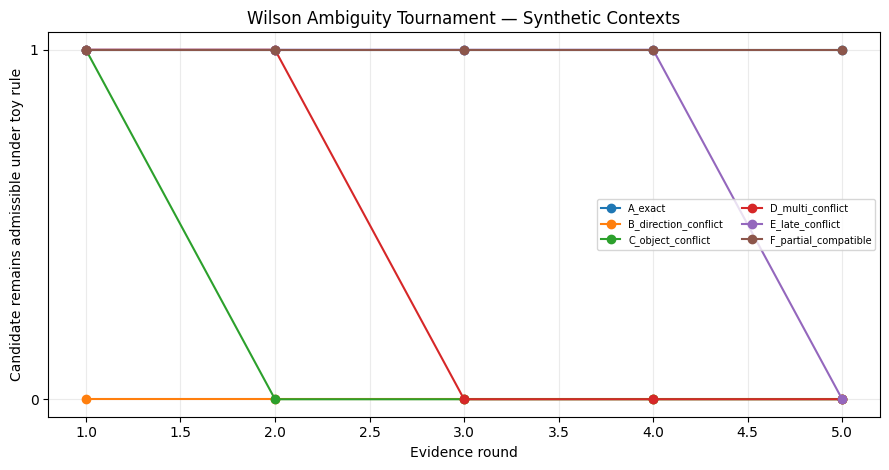

In [ ]:
def pack3_wilson_ambiguity_tournament():
    evidence = [
        ('motion', 'left'),
        ('object', 'vehicle'),
        ('speed', 'slow'),
        ('surface', 'wet'),
        ('light', 'low'),
    ]
    candidates = {
        'A_exact': {'motion':'left','object':'vehicle','speed':'slow','surface':'wet','light':'low'},
        'B_direction_conflict': {'motion':'right','object':'vehicle','speed':'slow','surface':'wet','light':'low'},
        'C_object_conflict': {'motion':'left','object':'person','speed':'slow','surface':'wet','light':'low'},
        'D_multi_conflict': {'motion':'left','object':'vehicle','speed':'fast','surface':'dry','light':'low'},
        'E_late_conflict': {'motion':'left','object':'vehicle','speed':'slow','surface':'wet','light':'bright'},
        'F_partial_compatible': {'motion':'left','object':'vehicle','surface':'wet'},
    }

    active = set(candidates)
    seen = []
    rows = []
    for round_index, (key, value) in enumerate(evidence, 1):
        seen.append((key, value))
        for name in list(active):
            candidate = candidates[name]
            if key in candidate and candidate[key] != value:
                active.remove(name)

        for name, candidate in candidates.items():
            support = sum(1 for k, v in seen if k in candidate and candidate[k] == v)
            contradictions = sum(1 for k, v in seen if k in candidate and candidate[k] != v)
            coverage = sum(1 for k, _ in seen if k in candidate) / len(seen)
            rows.append({
                'round': round_index,
                'evidence_revealed': f'{key}={value}',
                'candidate': name,
                'active': name in active,
                'support': support,
                'contradictions': contradictions,
                'coverage': coverage,
            })
    return pd.DataFrame(rows)

wilson_tournament_df = pack3_wilson_ambiguity_tournament()
display(wilson_tournament_df)

final_round = wilson_tournament_df[wilson_tournament_df['round'] == wilson_tournament_df['round'].max()]
display(final_round.sort_values(['active','support','coverage'], ascending=[False,False,False]))

pivot_active = wilson_tournament_df.pivot(index='round', columns='candidate', values='active').astype(int)
fig, ax = plt.subplots(figsize=(9, 4.8))
for candidate in pivot_active.columns:
    ax.plot(pivot_active.index, pivot_active[candidate], marker='o', label=candidate)
ax.set_xlabel('Evidence round')
ax.set_ylabel('Candidate remains admissible under toy rule')
ax.set_yticks([0, 1])
ax.set_title('Wilson Ambiguity Tournament — Synthetic Contexts')
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.25)
plt.tight_layout()
wilson_png = OUTPUT_DIR / 'Wilson_ambiguity_tournament.png'
plt.savefig(wilson_png, dpi=170, bbox_inches='tight')
plt.show()

## 11.7 Observer Resolution Limits

The same recurrence is deliberately degraded through several artificial observation channels: exact labels, coordinate sums, unordered coordinate pairs, Manhattan radius, x-coordinate only, binary zero/other, and parity only.

For each channel we measure how much of the eight-phase position is visible in a single observation and how much temporal context is needed to recover the full phase.

,observer_channel,phase_information_bits_single_observation,fraction_of_3bit_phase_information,single_observation_unique_phase_fraction,minimum_context_for_full_phase_recovery
0,exact,2.750000,0.916667,0.750,2
1,sum,2.250000,0.750000,0.250,2
2,unordered_pair,2.250000,0.750000,0.250,2
3,manhattan,2.250000,0.750000,0.250,2
4,x_only,2.155639,0.718546,0.375,2
5,binary_zero_other,0.811278,0.270426,0.000,6
6,parity,1.000000,0.333333,0.000,4


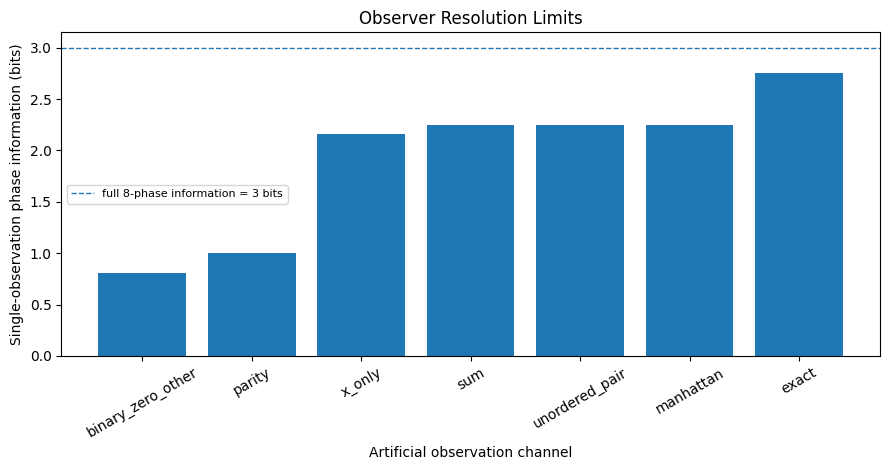

In [ ]:
def pack3_observation_channel(token, kind):
    if token == DELAY_TOKEN:
        if kind == 'exact':
            return token
        if kind == 'binary_zero_other':
            return 'other'
        if kind == 'parity':
            return 'E'
        return 'D'

    x, y = map(int, token.split(','))
    if kind == 'exact':
        return token
    if kind == 'sum':
        return str(x + y)
    if kind == 'unordered_pair':
        return str(tuple(sorted((x, y))))
    if kind == 'manhattan':
        return str(abs(x) + abs(y))
    if kind == 'x_only':
        return str(x)
    if kind == 'binary_zero_other':
        return 'zero' if (x, y) == (0, 0) else 'other'
    if kind == 'parity':
        return 'E' if (x + y) % 2 == 0 else 'O'
    raise KeyError(kind)


def pack3_symbol_entropy(values):
    counts = Counter(values)
    total = sum(counts.values())
    return -sum((n/total) * math.log2(n/total) for n in counts.values())


def pack3_observer_resolution():
    kinds = ['exact','sum','unordered_pair','manhattan','x_only','binary_zero_other','parity']
    rows = []
    phase_entropy = math.log2(len(P2_CYCLE))
    for kind in kinds:
        observed_cycle = [pack3_observation_channel(s, kind) for s in P2_CYCLE]
        obs_entropy = pack3_symbol_entropy(observed_cycle)
        counts = Counter(observed_cycle)
        unique_fraction = sum(counts[x] == 1 for x in observed_cycle) / len(observed_cycle)

        minimum_context = np.nan
        for context_length in range(1, 17):
            windows = [tuple(observed_cycle[(phase + j) % len(observed_cycle)] for j in range(context_length)) for phase in range(len(observed_cycle))]
            if len(set(windows)) == len(observed_cycle):
                minimum_context = context_length
                break

        rows.append({
            'observer_channel': kind,
            'phase_information_bits_single_observation': obs_entropy,
            'fraction_of_3bit_phase_information': obs_entropy / phase_entropy,
            'single_observation_unique_phase_fraction': unique_fraction,
            'minimum_context_for_full_phase_recovery': minimum_context,
        })
    return pd.DataFrame(rows)

observer_resolution_df = pack3_observer_resolution()
display(observer_resolution_df)

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_df = observer_resolution_df.sort_values('phase_information_bits_single_observation')
ax.bar(plot_df['observer_channel'], plot_df['phase_information_bits_single_observation'])
ax.axhline(3.0, linestyle='--', linewidth=1, label='full 8-phase information = 3 bits')
ax.set_ylabel('Single-observation phase information (bits)')
ax.set_xlabel('Artificial observation channel')
ax.set_title('Observer Resolution Limits')
ax.tick_params(axis='x', rotation=30)
ax.legend(fontsize=8)
plt.tight_layout()
observer_png = OUTPUT_DIR / 'P2_observer_resolution.png'
plt.savefig(observer_png, dpi=170, bbox_inches='tight')
plt.show()

## 11.8 Counterfactual Twin Environment Lab

Two synthetic systems begin with the **same fixed P2 recurrence and the same initial auxiliary state**. Only the external forcing differs. A separate bounded response variable is allowed to diverge while the kernel stream is verified to remain identical.

The response equation and forcing signals are generic simulation variables. They do not define Wilson, QRTM, or a physical QTET mechanism.

,kernel_streams_identical,mean_absolute_response_divergence,maximum_absolute_response_divergence,response_correlation
0,True,0.403285,1.180257,-0.049625


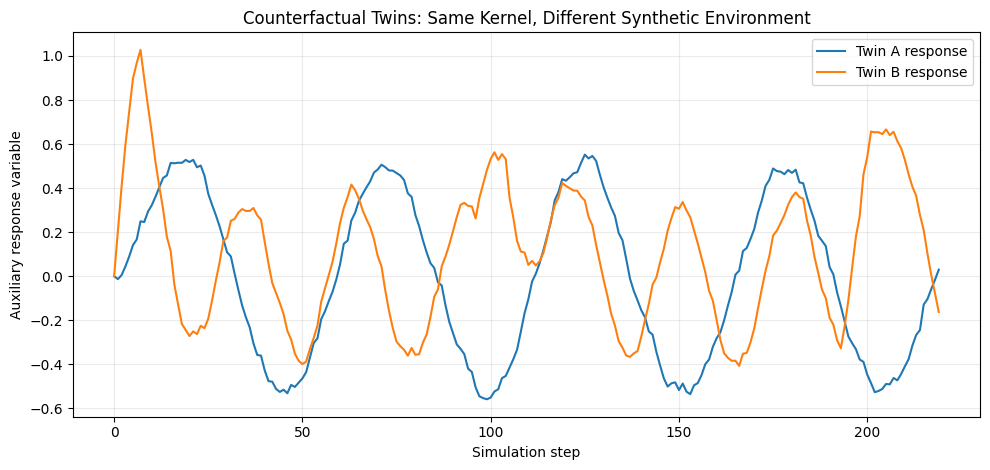

In [ ]:
def pack3_counterfactual_twins(cycles=60, seed=404):
    local_rng = np.random.default_rng(seed)
    labels = P2_CYCLE * int(cycles)
    n = len(labels)
    t = np.arange(n)

    state_drive = {state: value for state, value in zip(UNIQUE_STATES, np.linspace(-0.4, 0.4, len(UNIQUE_STATES)))}
    forcing_A = 0.7 * np.sin(2*np.pi*t/53) + 0.10 * local_rng.normal(size=n)
    forcing_B = 0.7 * np.sin(2*np.pi*t/29 + 1.2) + 0.10 * local_rng.normal(size=n)
    forcing_B += ((t % 97) < 8) * 1.2

    response_A = np.zeros(n)
    response_B = np.zeros(n)
    for i in range(1, n):
        common = state_drive[labels[i]]
        response_A[i] = 0.88 * response_A[i-1] + 0.12 * forcing_A[i] + 0.06 * common
        response_B[i] = 0.88 * response_B[i-1] + 0.12 * forcing_B[i] + 0.06 * common

    return pd.DataFrame({
        'step': t,
        'kernel_event': labels,
        'forcing_A': forcing_A,
        'forcing_B': forcing_B,
        'response_A': response_A,
        'response_B': response_B,
        'absolute_response_divergence': np.abs(response_A - response_B),
    })

twin_df = pack3_counterfactual_twins()
twin_summary_df = pd.DataFrame([{
    'kernel_streams_identical': True,
    'mean_absolute_response_divergence': twin_df['absolute_response_divergence'].mean(),
    'maximum_absolute_response_divergence': twin_df['absolute_response_divergence'].max(),
    'response_correlation': np.corrcoef(twin_df['response_A'], twin_df['response_B'])[0, 1],
}])
display(twin_summary_df)

fig, ax = plt.subplots(figsize=(10, 4.8))
window = twin_df.iloc[:220]
ax.plot(window['step'], window['response_A'], label='Twin A response')
ax.plot(window['step'], window['response_B'], label='Twin B response')
ax.set_xlabel('Simulation step')
ax.set_ylabel('Auxiliary response variable')
ax.set_title('Counterfactual Twins: Same Kernel, Different Synthetic Environment')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
twin_png = OUTPUT_DIR / 'P2_counterfactual_twins.png'
plt.savefig(twin_png, dpi=170, bbox_inches='tight')
plt.show()

## 11.9 Temporal-Stretch Recognition with Dynamic Time Warping

The canonical recurrence is time-stretched by assigning random durations to each observed event, then a small amount of symbol corruption is added. Dynamic time warping (DTW) compares the stretched stream to the unstretched canonical template. Shuffled-event streams serve as decoys.

This tests recognition under altered ordinary playback timing; it does not redefine `Delay(200)` or Echo Meridian temporal ordering.

,stretch_sigma,case,mean,std
0,0.0,canonical_stretched,0.026823,0.010943
1,0.0,shuffled_decoy,0.595833,0.100119
2,0.4,canonical_stretched,0.025269,0.012908
3,0.4,shuffled_decoy,0.554467,0.093089
4,0.8,canonical_stretched,0.034027,0.010994
5,0.8,shuffled_decoy,0.456390,0.085971
6,1.2,canonical_stretched,0.034598,0.009585
7,1.2,shuffled_decoy,0.362328,0.091984
8,1.6,canonical_stretched,0.037289,0.009121
9,1.6,shuffled_decoy,0.260116,0.091947


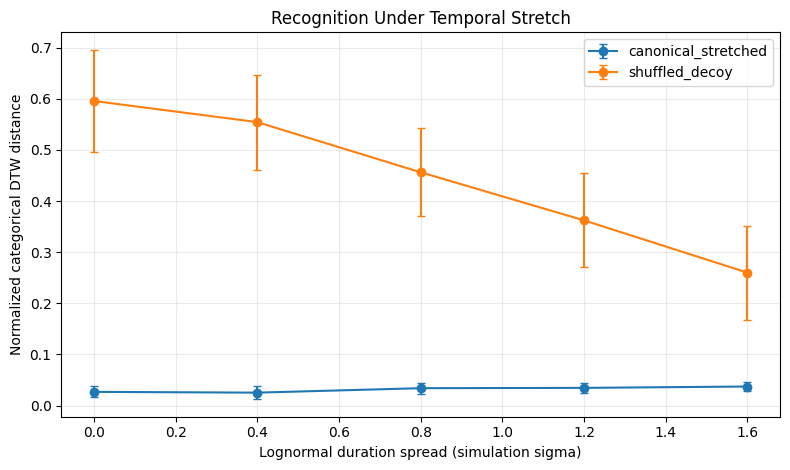

In [ ]:
def pack3_dtw_categorical(a, b):
    n, m = len(a), len(b)
    previous = np.full(m + 1, np.inf)
    previous[0] = 0.0
    for i in range(1, n + 1):
        current = np.full(m + 1, np.inf)
        for j in range(1, m + 1):
            cost = 0.0 if a[i-1] == b[j-1] else 1.0
            current[j] = cost + min(previous[j], current[j-1], previous[j-1])
        previous = current
    return float(previous[m] / max(n, m))


def pack3_stretch_events(sequence, sigma, local_rng):
    stretched = []
    for state in sequence:
        duration = max(1, int(round(np.exp(local_rng.normal(0, sigma)))))
        stretched.extend([state] * duration)
    return stretched


def pack3_temporal_stretch_sweep(stretch_sigmas=(0,0.4,0.8,1.2,1.6), trials=120, substitution_rate=0.05):
    template = P2_CYCLE * 4
    rows = []
    for sigma in stretch_sigmas:
        for trial in range(trials):
            local_rng = np.random.default_rng(50000 + trial)
            observed = pack3_stretch_events(template, sigma, local_rng)
            n_sub = max(1, int(substitution_rate * len(observed)))
            for idx in local_rng.choice(len(observed), size=n_sub, replace=False):
                observed[idx] = local_rng.choice(UNIQUE_STATES)

            decoy_cycle = P2_CYCLE.copy()
            local_rng.shuffle(decoy_cycle)
            decoy = pack3_stretch_events(decoy_cycle * 4, sigma, local_rng)

            rows.append({'stretch_sigma': sigma, 'case': 'canonical_stretched', 'normalized_dtw_distance': pack3_dtw_categorical(template, observed)})
            rows.append({'stretch_sigma': sigma, 'case': 'shuffled_decoy', 'normalized_dtw_distance': pack3_dtw_categorical(template, decoy)})
    return pd.DataFrame(rows)

temporal_stretch_df = pack3_temporal_stretch_sweep()
temporal_stretch_summary_df = (
    temporal_stretch_df.groupby(['stretch_sigma','case'])['normalized_dtw_distance']
    .agg(['mean','std'])
    .reset_index()
)
display(temporal_stretch_summary_df)

fig, ax = plt.subplots(figsize=(8, 4.8))
for case, group in temporal_stretch_summary_df.groupby('case'):
    ax.errorbar(group['stretch_sigma'], group['mean'], yerr=group['std'], marker='o', capsize=3, label=case)
ax.set_xlabel('Lognormal duration spread (simulation sigma)')
ax.set_ylabel('Normalized categorical DTW distance')
ax.set_title('Recognition Under Temporal Stretch')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
stretch_png = OUTPUT_DIR / 'P2_temporal_stretch_DTW.png'
plt.savefig(stretch_png, dpi=170, bbox_inches='tight')
plt.show()

## 11.10 P2 Information Telescope

The earlier Predictive Information Horizon asked how much past context is needed to predict the **next** event. The telescope turns the question around: with a fixed amount of past context, how far into the recurrent future can the observer predict?

We calculate ordinary conditional Shannon entropy for horizons 1–24. This is information theory only, not thermodynamic entropy.

,context_length,prediction_horizon,conditional_entropy_bits
0,1,1,0.250016
1,1,2,0.249969
2,1,3,0.249984
3,1,4,0.250000
4,1,5,0.250016
5,1,6,0.250031
6,1,7,0.249984
7,1,8,0.000000
8,1,9,0.250016
9,1,10,0.249969


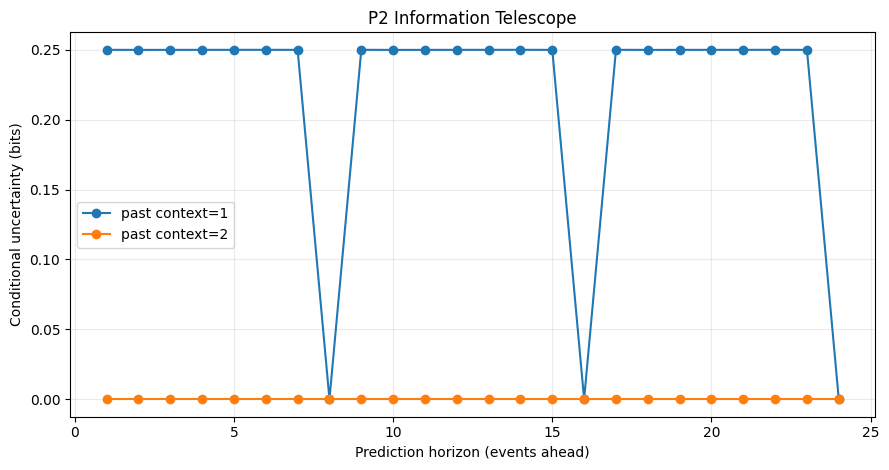

Maximum uncertainty with two-event context: 0.0
One-event context at horizon 8: 0.0


In [ ]:
def pack3_conditional_entropy_horizon(sequence, context_length, horizon):
    joint = Counter()
    contexts = Counter()
    total = 0
    for i in range(context_length, len(sequence) - horizon + 1):
        context = tuple(sequence[i-context_length:i])
        target = sequence[i + horizon - 1]
        joint[(context, target)] += 1
        contexts[context] += 1
        total += 1

    H = 0.0
    for context, n_context in contexts.items():
        p_context = n_context / total
        local_H = 0.0
        for (ctx, target), n in joint.items():
            if ctx == context:
                p = n / n_context
                local_H -= p * math.log2(p)
        H += p_context * local_H
    return H


def pack3_information_telescope(max_horizon=24, context_lengths=(1,2), cycles=2000):
    sequence = P2_CYCLE * int(cycles)
    rows = []
    for context_length in context_lengths:
        for horizon in range(1, max_horizon + 1):
            rows.append({
                'context_length': context_length,
                'prediction_horizon': horizon,
                'conditional_entropy_bits': pack3_conditional_entropy_horizon(sequence, context_length, horizon),
            })
    return pd.DataFrame(rows)

information_telescope_df = pack3_information_telescope()
display(information_telescope_df)

fig, ax = plt.subplots(figsize=(9, 4.8))
for context_length, group in information_telescope_df.groupby('context_length'):
    ax.plot(group['prediction_horizon'], group['conditional_entropy_bits'], marker='o', label=f'past context={context_length}')
ax.set_xlabel('Prediction horizon (events ahead)')
ax.set_ylabel('Conditional uncertainty (bits)')
ax.set_title('P2 Information Telescope')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
telescope_png = OUTPUT_DIR / 'P2_information_telescope.png'
plt.savefig(telescope_png, dpi=170, bbox_inches='tight')
plt.show()

print('Maximum uncertainty with two-event context:', information_telescope_df.loc[information_telescope_df.context_length == 2, 'conditional_entropy_bits'].max())
print('One-event context at horizon 8:', information_telescope_df.loc[(information_telescope_df.context_length == 1) & (information_telescope_df.prediction_horizon == 8), 'conditional_entropy_bits'].iloc[0])

## 11.11 Export Pack III Results

In [ ]:
pack3_exports = {
    'P2_unknown_phase_synchronization.csv': phase_sync_df,
    'P2_predictive_state_summary.csv': predictive_summary_df,
    'P2_predictive_state_contexts.csv': predictive_contexts,
    'P3_tomography_recovery.csv': tomography_df,
    'Tensor_braid_crossing_matrix.csv': braid_crossing_df,
    'QRTM_phase_torus_slip_scan.csv': phase_torus_df,
    'Wilson_ambiguity_tournament.csv': wilson_tournament_df,
    'P2_observer_resolution.csv': observer_resolution_df,
    'P2_counterfactual_twins_summary.csv': twin_summary_df,
    'P2_counterfactual_twins_timeseries.csv': twin_df,
    'P2_temporal_stretch_DTW_trials.csv': temporal_stretch_df,
    'P2_temporal_stretch_DTW_summary.csv': temporal_stretch_summary_df,
    'P2_information_telescope.csv': information_telescope_df,
}

for filename, dataframe in pack3_exports.items():
    path = OUTPUT_DIR / filename
    dataframe.to_csv(path, index=True if filename == 'Tensor_braid_crossing_matrix.csv' else False)
    print('saved', path)

saved /content/qtet_outputs/P2_unknown_phase_synchronization.csv
saved /content/qtet_outputs/P2_predictive_state_summary.csv
saved /content/qtet_outputs/P2_predictive_state_contexts.csv
saved /content/qtet_outputs/P3_tomography_recovery.csv
saved /content/qtet_outputs/Tensor_braid_crossing_matrix.csv
saved /content/qtet_outputs/QRTM_phase_torus_slip_scan.csv
saved /content/qtet_outputs/Wilson_ambiguity_tournament.csv
saved /content/qtet_outputs/P2_observer_resolution.csv
saved /content/qtet_outputs/P2_counterfactual_twins_summary.csv
saved /content/qtet_outputs/P2_counterfactual_twins_timeseries.csv
saved /content/qtet_outputs/P2_temporal_stretch_DTW_trials.csv
saved /content/qtet_outputs/P2_temporal_stretch_DTW_summary.csv
saved /content/qtet_outputs/P2_information_telescope.csv


## 11.12 Pack III Validation

These checks verify notebook mechanics and the simulation claims actually produced above. They do not adjudicate the physical interpretation of the framework.

In [ ]:
assert CANONICAL_P2 == ((3,3),(0,0),(0,1),(1,2),(2,1),(1,0),(0,0))
assert DELAY == 200

# Exact phase synchronization: one event is ambiguous because 0,0 repeats; two events resolve phase.
phase_exact = phase_sync_df[phase_sync_df['erasure_rate'] == 0.0]
assert phase_exact.loc[phase_exact.context_length == 1, 'unique_phase_probability'].iloc[0] < 1.0
assert phase_exact.loc[phase_exact.context_length == 2, 'unique_phase_probability'].iloc[0] == 1.0

# Finite predictive context resolves future-block ambiguity by history length 2.
assert predictive_summary_df.loc[predictive_summary_df.history_length == 1, 'weighted_future_block_entropy_bits'].iloc[0] > 0
assert predictive_summary_df.loc[predictive_summary_df.history_length == 2, 'weighted_future_block_entropy_bits'].iloc[0] == 0

# Tomography improves as more independent shadows are averaged.
assert tomography_df.iloc[-1]['mean_distance_rank_correlation'] > tomography_df.iloc[0]['mean_distance_rank_correlation']

# Braid crossing multiset is invariant to relabeling in this visualization.
assert crossing_signature == permuted_signature

# Observer and telescope sanity checks.
assert observer_resolution_df.loc[observer_resolution_df.observer_channel == 'exact', 'minimum_context_for_full_phase_recovery'].iloc[0] == 2
assert information_telescope_df.loc[information_telescope_df.context_length == 2, 'conditional_entropy_bits'].max() < 1e-10

# DTW should keep time-stretched canonical streams closer than shuffled-order decoys at every tested stretch level.
for sigma in temporal_stretch_summary_df['stretch_sigma'].unique():
    sub = temporal_stretch_summary_df[temporal_stretch_summary_df['stretch_sigma'] == sigma]
    canonical_mean = sub.loc[sub['case'] == 'canonical_stretched', 'mean'].iloc[0]
    decoy_mean = sub.loc[sub['case'] == 'shuffled_decoy', 'mean'].iloc[0]
    assert canonical_mean < decoy_mean

print('Creative Simulation Pack III validation passed.')

Creative Simulation Pack III validation passed.


## 11.13 Pack III Takeaways

The strongest computational themes to inspect after execution are:

- **Phase observability:** repeated coordinate identity does not imply repeated traversal role; consecutive context resolves the ambiguity in this exact stream.
- **Predictive-state structure:** finite two-event history removes the short-future uncertainty created by coordinate-only observation.
- **Tomographic recovery:** many low-dimensional views progressively recover the relational geometry of a hidden simulation embedding.
- **Representation vs. identity:** braid labels can change while a label-free crossing multiset remains the same.
- **Resolution limits:** heavily degraded observation channels can still recover phase if enough temporal context remains.
- **Kernel/environment separation:** the counterfactual twins keep the identical kernel sequence while a separate simulation response diverges under different external forcing.
- **Warped-time recognition:** categorical DTW recognizes the same event order despite large timing distortion better than shuffled-order decoys in the tested parameter range.
- **Information telescope:** two-event context determines the entire exact periodic future in this finite recurrence, while one-event context retains the repeated-`0,0` ambiguity except at recurrence-aligned horizons.

All of these are computational properties of the explicit simulation constructions above. They should be interpreted as experiments on representation and recoverability unless separately connected to empirical data.